In [1]:
#Imports

#custom
import cvp
import cvp_baseline_additions as cba

#plotting
import matplotlib.pyplot as plt
import arcadia_pycolor as apc
apc.mpl.setup()
apc.plotly.setup()

#matrices
import numpy as np

#basic tools
import random
from importlib import reload 

#stats
from scipy.cluster.hierarchy import fcluster

#ml
from sklearn.manifold import TSNE

In [2]:
n_fovs_2_analyze=9

#Early Stationary Phase Chlorella UV Mutants

#CHLORELLA UV 16 #CHANGE AFTER SEGMENTATION IS DONE!
fig_prefix_20260105_203447_582="20260105_203447_582"
#CHLORELLA UV 22
fig_prefix_20260105_125955_886="20260105_125955_886"
#CHLORELLA UV 30
fig_prefix_20260105_161353_802="20260105_161353_802"

#-------------------------------------------------------------------------------------------------------------#

#Late Stationary Phase Chlorella UV Mutants

#CHLORELLA UV 16 
fig_prefix_20260112_161051_665="20260112_161051_665"
#CHLORELLA UV 22
fig_prefix_20260112_112101_320="20260112_112101_320"
#CHLORELLA UV 30
fig_prefix_20260112_135035_609="20260112_135035_609"


# fig_prefix_20260111_165957_639,
fig_prefices=[fig_prefix_20260105_203447_582,
              fig_prefix_20260105_125955_886,
              fig_prefix_20260105_161353_802,
              
              
              fig_prefix_20260112_161051_665,
              fig_prefix_20260112_112101_320,
              fig_prefix_20260112_135035_609]


col_titles = ["16C e.stat",
              "22C e.stat", 
              "30C e.stat", 
              
              "16C l.stat",
              "22C l.stat", 
              "30C l.stat"]

#color scheme for experimental conditions
ytick_colors=[apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy]
cell_count_cutoff=50

In [3]:
# THIS IS WHERE THE ANALYSIS BEGINS!

In [9]:
# Load Data (this cell will take a couple of minutes)

# Zroots is where the data is read from
zroots=[]
zpaths=[]
# prebuild JSONL Path/Indices to make reading data faster
jsonl_paths=[]
jsonly_idces=[]

for fp in fig_prefices:
    ZARR_PATH ='zarrs/experiment_batches_'+fp+'_features.zarr'
    JSONL_PATH='jsonls/experiment_batches_'+fp+'_features.jsonl'

    zroots.append(cvp.ExperimentStore(ZARR_PATH,JSONL_PATH))
    zpaths.append(ZARR_PATH)
    
    jsonl_paths.append(JSONL_PATH)
    #prebulding these indices allows for faster recall of the data
    jsonly_idces.append(cvp.build_jsonl_offset_index(JSONL_PATH))

#auto check for the empty wells
# The experiment IDs being hardcoded are due to the legacy of this notebook (previously we were looking at 20+ conditions, not just 6)
experiments_to_check=[0,1,2,3,4,5]

dead_wells, dead_ids = cvp.compute_dead_wells_and_ids(
    zroots=zroots,
    experiments_to_check=[0,1,2,3,4,5],
    n_fovs=n_fovs_2_analyze,
    cell_count_cutoff=cell_count_cutoff,
)

# these are the features that are automatically extracted from arcadia's microscopy tools
cellpose_features=zroots[0].get_cell_properties(0, 0, "BF").columns.tolist()
cellpose_features[0]='count'

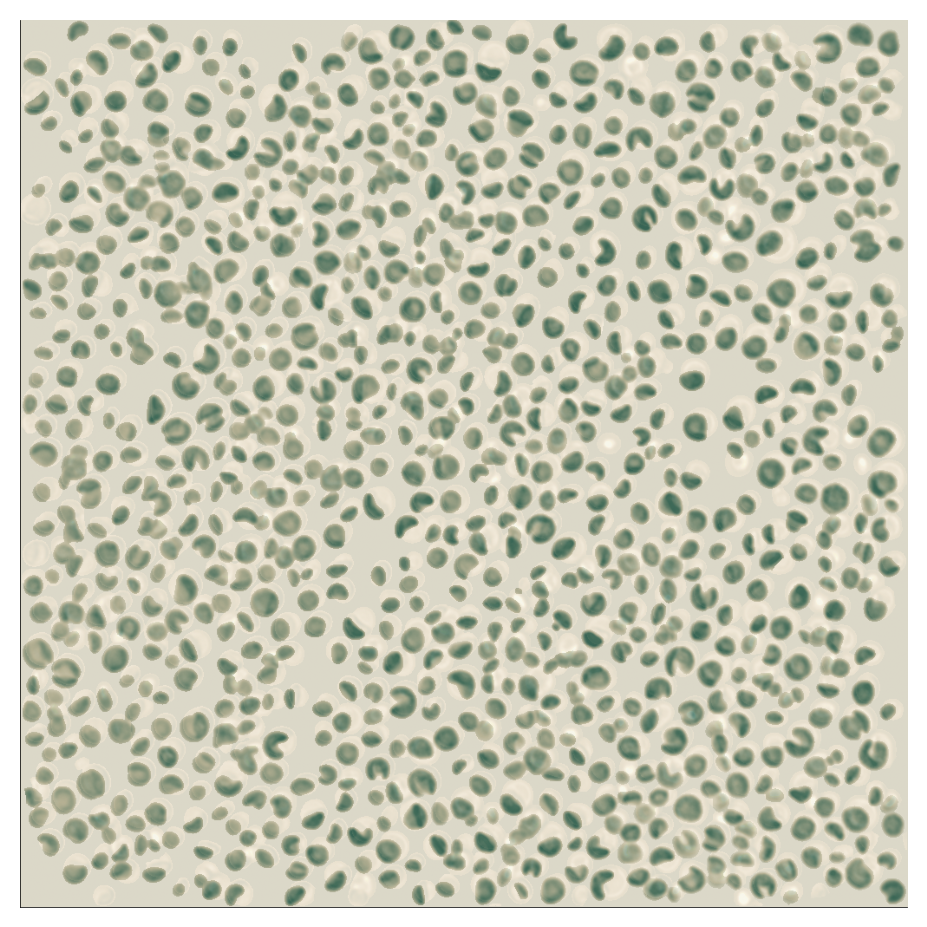

In [10]:
#view the raw and processed images of any mutant in any condition
#reload(cvp)
#example_codition_id (0-5 is equivalent to e.16, e.22, e.30, l.16, l.22, l.30)
example_condition_id=3
example_strain=68
example_field_of_view=4

cvp.showcase_clone_images_1_by_1(zroots,
                             experiment=example_condition_id,
                             field_of_view=example_field_of_view,
                             well=example_strain,
                             f_size=[16, 16],
                             f_size_2=[16, 16],
                             show_labels=False,
                             marker_size_1=6,
                             marker_size_2=4,
                             marker_color_bf='yellow',
                             marker_color_cy='red',
                             hide_in_cell=True)

e_stat_16 (864, 40) NaNs: 0 Infs: 0
e_stat_22 (864, 40) NaNs: 0 Infs: 0
e_stat_30 (864, 40) NaNs: 0 Infs: 0
l_stat_16 (864, 40) NaNs: 0 Infs: 0
l_stat_22 (864, 40) NaNs: 0 Infs: 0
l_stat_30 (864, 40) NaNs: 0 Infs: 0


'\ntrain_conditions = ["e_stat_22", "e_stat_30", "l_stat_16", "l_stat_22", "l_stat_30"]\ntest_condition = "e_stat_16"\n\ny_pred, metrics, model = cvp.train_and_predict(\n    training_data_finite,\n    train_conditions,\n    test_condition,\n    model_type="ridge",\n    alpha=100\n)\n\nprint(metrics["r2_overall"])\n'

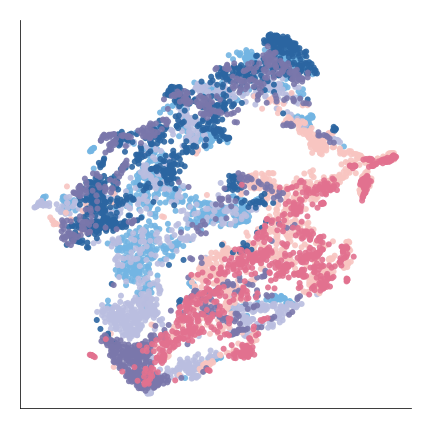

In [11]:
#this is an important cell to run and takes ~5 minutes

reload(cvp)
exp_conditions=["e_stat_16","e_stat_22","e_stat_30","l_stat_16","l_stat_22","l_stat_30"]
training_data, training_feature_labels, feature_slices = cvp.build_training_data(
    zroots,
    exp_conditions=exp_conditions,
    experiments_to_compare=[0,1,2,3,4,5],
    n_fovs_2_analyze=n_fovs_2_analyze,
    exclude_features=["moments_hu-4", "moments_hu-5", "moments_hu-6"], #"inertia_tensor-1-0","inertia_tensor-0-1","orientation",
    include_pixel_intensity=True,
    pixel_intensity_channels=("BF", "CY5"),
)

# ---------------------------------
# 1. Impute NaNs/infs within each condition matrix
#    while preserving the row structure
# ---------------------------------


training_data_finite = {
    cond: cvp.make_condition_matrix_finite(training_data[cond])
    for cond in exp_conditions
}

# optional sanity check
for cond in exp_conditions:
    print(
        cond,
        training_data_finite[cond].shape,
        "NaNs:", np.isnan(training_data_finite[cond]).sum(),
        "Infs:", np.isinf(training_data_finite[cond]).sum()
    )

# ---------------------------------
# 2. Stack conditions for PCA, removing dead_ids exactly as before
# ---------------------------------
all_dat = np.vstack([
    cvp.remove_rows_cols(training_data_finite[exp_conditions[0]], row_indices=dead_ids, col_indices=[]),
    cvp.remove_rows_cols(training_data_finite[exp_conditions[1]], row_indices=dead_ids, col_indices=[]),
    cvp.remove_rows_cols(training_data_finite[exp_conditions[2]], row_indices=dead_ids, col_indices=[]),
    cvp.remove_rows_cols(training_data_finite[exp_conditions[3]], row_indices=dead_ids, col_indices=[]),
    cvp.remove_rows_cols(training_data_finite[exp_conditions[4]], row_indices=dead_ids, col_indices=[]),
    cvp.remove_rows_cols(training_data_finite[exp_conditions[5]], row_indices=dead_ids, col_indices=[]),
])


#print("all_dat shape:", all_dat.shape)
#print("NaNs in all_dat:", np.isnan(all_dat).sum())
#print("Infs in all_dat:", np.isinf(all_dat).sum())

# ---------------------------------
# 3. PCA
# ---------------------------------
experiment_as_pcs, experiment_pc_evecs, experiment_pc_evals, experiment_pc_mean_value = cvp.pca_on_np_array(all_dat)

# ---------------------------------
# 4. t-SNE
#    use the actual number of columns, not 44
# ---------------------------------
random.seed(28)
n_features = all_dat.shape[1]

experiment_X_embedded = TSNE(
    n_components=2,
    learning_rate='auto',
    init='random',
    perplexity=200
).fit_transform(experiment_as_pcs[:, 0:n_features])

# ---------------------------------
# 5. Plot t-SNE by condition
# ---------------------------------
cvp.plot_tsne(
    input_dat=all_dat,
    exp_embedding=experiment_X_embedded,
    exp_colors=ytick_colors,
    n_fovs=n_fovs_2_analyze,
    dead_well_ids=dead_ids,
    figtitle='tsne_colored_by_experimental_condition',
    hide_in_cell=False
)

# ---------------------------------
# 6. Ridge model
#    use the finite version of training_data
# ---------------------------------

'''
train_conditions = ["e_stat_22", "e_stat_30", "l_stat_16", "l_stat_22", "l_stat_30"]
test_condition = "e_stat_16"

y_pred, metrics, model = cvp.train_and_predict(
    training_data_finite,
    train_conditions,
    test_condition,
    model_type="ridge",
    alpha=100
)

print(metrics["r2_overall"])
'''

In [245]:
training_data_finite = {
    cond: cvp.make_condition_matrix_finite(training_data[cond])
    for cond in exp_conditions
}

# optional sanity check
for cond in exp_conditions:
    print(
        cond,
        training_data_finite[cond].shape,
        "NaNs:", np.isnan(training_data_finite[cond]).sum(),
        "Infs:", np.isinf(training_data_finite[cond]).sum()
    )

# ---------------------------------
# 2. Stack conditions for PCA, removing dead_ids exactly as before
# ---------------------------------
all_dat = np.vstack([
    cvp.remove_rows_cols(training_data_finite[exp_conditions[0]], row_indices=dead_ids, col_indices=[]),
    cvp.remove_rows_cols(training_data_finite[exp_conditions[1]], row_indices=dead_ids, col_indices=[]),
    cvp.remove_rows_cols(training_data_finite[exp_conditions[2]], row_indices=dead_ids, col_indices=[]),
    cvp.remove_rows_cols(training_data_finite[exp_conditions[3]], row_indices=dead_ids, col_indices=[]),
    cvp.remove_rows_cols(training_data_finite[exp_conditions[4]], row_indices=dead_ids, col_indices=[]),
    cvp.remove_rows_cols(training_data_finite[exp_conditions[5]], row_indices=dead_ids, col_indices=[]),
])

#temporarily try this
reload(cvp)
training_data_finite, hu_indices, hu_labels = cvp.signed_log_transform_hu_features(
    training_data_finite,
    training_feature_labels,
    log_base="log10",
    eps=1e-12,
    in_place=False,
)

e_stat_16 (864, 40) NaNs: 0 Infs: 0
e_stat_22 (864, 40) NaNs: 0 Infs: 0
e_stat_30 (864, 40) NaNs: 0 Infs: 0
l_stat_16 (864, 40) NaNs: 0 Infs: 0
l_stat_22 (864, 40) NaNs: 0 Infs: 0
l_stat_30 (864, 40) NaNs: 0 Infs: 0


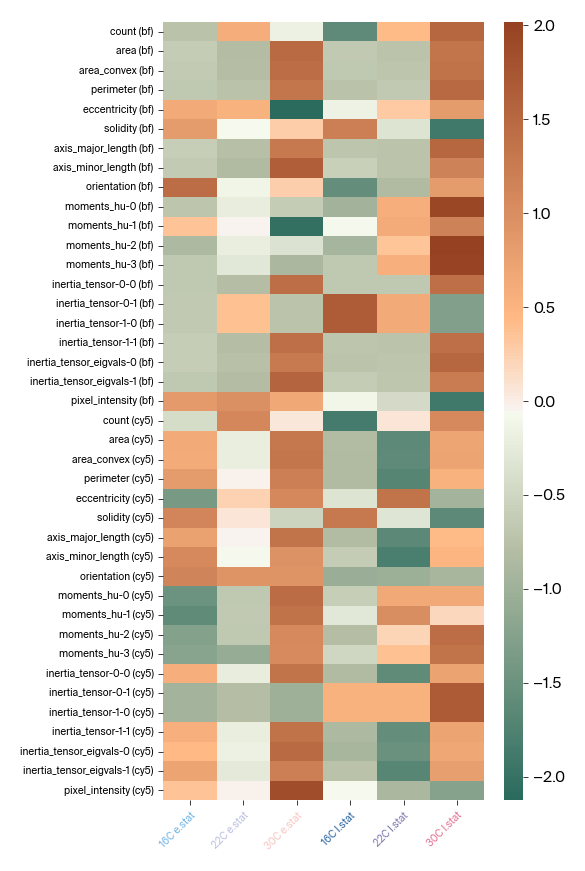

In [246]:
reload(cvp)
fig, ax, plot_df = cvp.plot_mean_relative_feature_values_across_conditions(
    training_data=training_data_finite,
    training_feature_labels=training_feature_labels,
    condition_order=exp_conditions,
    col_titles=np.array(col_titles),
    orientation="vertical",
    xtick_colors=[apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy],
    figsize=(8, 12),
    show_title=False,
    cbar_shrink=1,
    cbar_aspect=40,
    save=True
)

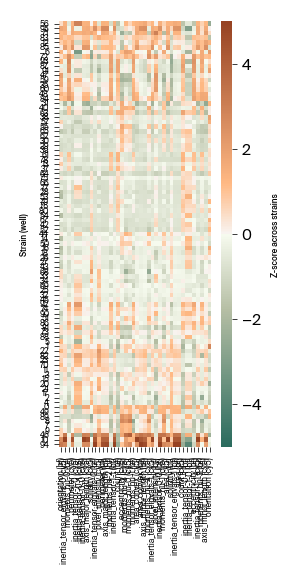

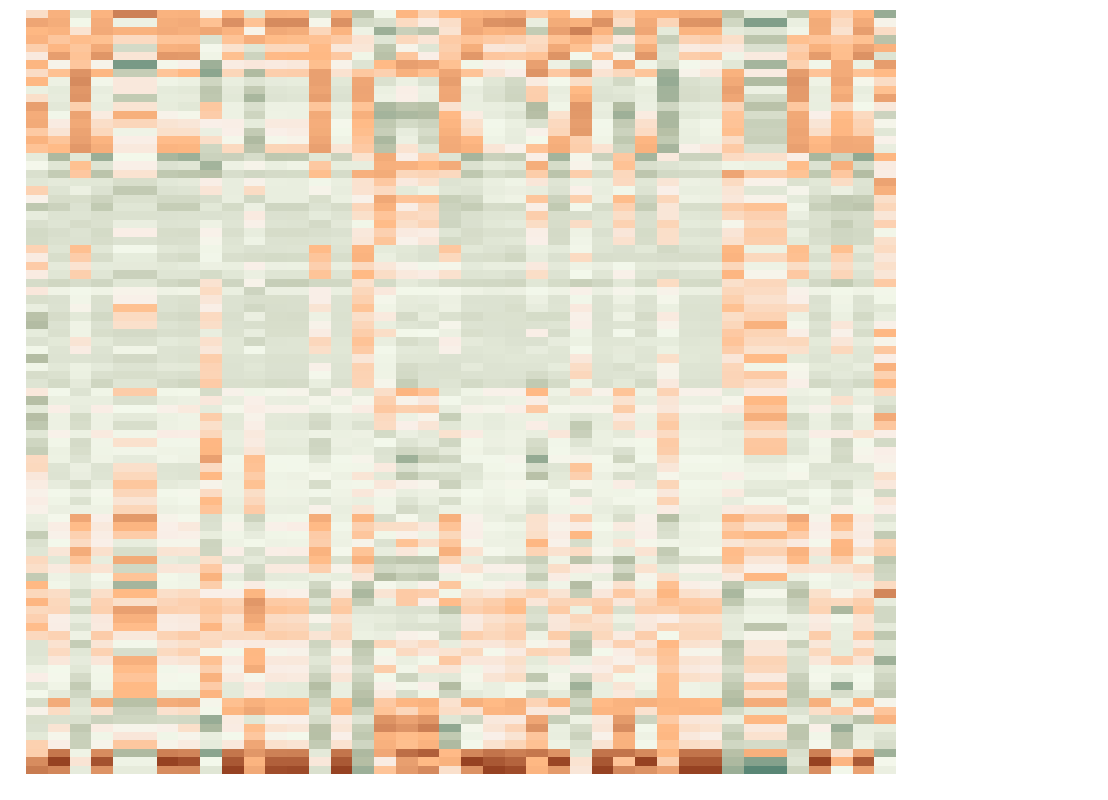

In [310]:
#what features are each strain expressing?

reload(cvp)
'''
fig, ax, strain_heatmap_df = cvp.plot_all_strain_feature_heatmap(
    training_data=training_data_finite,        # or training_data_hu_log
    training_feature_labels=training_feature_labels,
    temperature=30,                            # 16, 22, or 30
    growth_stage="e_stat",                     # "e_stat"/"early" or "l_stat"/"late"
    fovs=0,                                    # 0 = one FoV; [0,1,2] or "all" to combine
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    exclude_features=["moments_hu-4", "moments_hu-5", "moments_hu-6"],   # or "moments_hu" to drop them all
    normalize="zscore",                        # per feature, across strains
    sort_features=True,                        # order features by variance across strains
    cluster_strains=True,                      # group phenotypically similar strains
    orientation="horizontal",                    # features on y, strains on x
    figsize=(10, 14),
    font_size=8,
    show_title=False,
    cbar_shrink=1,
    cbar_aspect=40,
    vmin=-5,
    vmax=5,
    save=True,
    figtitle="all_strain_feature_heatmap_e_stat_22_fov0",
)
'''

reload(cvp)
reload(cba)

show_labels = False


fig, ax, strain_heatmap_df, strain_pfig = cba.plot_all_strain_feature_heatmap(
    training_data=training_data_finite,        # or training_data_hu_log
    training_feature_labels=training_feature_labels,
    temperature=30,                            # 16, 22, or 30
    growth_stage="e_stat",                     # "e_stat"/"early" or "l_stat"/"late"
    fovs=[0,1,2,3,4,5,6,7,8],                                    # 0 = one FoV; [0,1,2] or "all" to combine
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    exclude_features=["moments_hu-4", "moments_hu-5", "moments_hu-6"],
    normalize="zscore",                        # per feature, across strains
    sort_features=True,                        # order features by variance across strains
    cluster_strains=True,                      # group phenotypically similar strains
    orientation="horizontal",
    figsize=(4, 8),
    font_size=8,
    show_title=False,
    cbar_shrink=1,
    cbar_aspect=40,
    vmin=-5,
    vmax=5,
    save=True,
    figtitle="all_strain_feature_heatmap_e_stat_22_average_of_all_fovs",

    # --- Plotly version ---
    backend="both",                            # "plotly" for the interactive one only
    hover_fields=["strain", "feature", "value"],
    plotly_show_xticklabels=show_labels,
    plotly_show_yticklabels=show_labels,
    plotly_layout={} if show_labels else {"xaxis_title_text": "", "yaxis_title_text": ""},
    plotly_cbar=False
)

/Users/rockwell/repos/2026-chlorella-phenotyping/cvp.py:9931: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



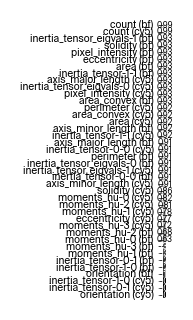

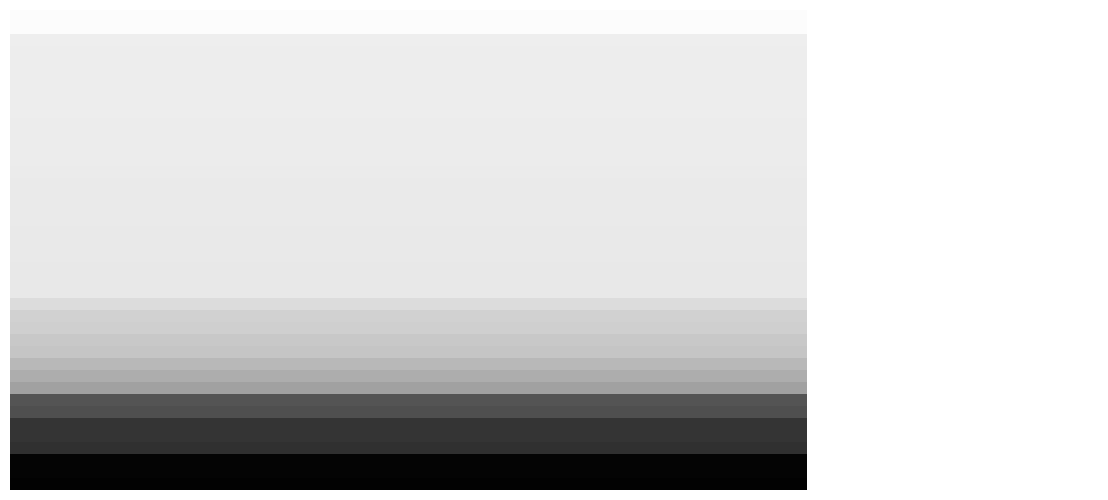

In [309]:
reload(cvp)
reload(cba)

icc_results = cvp.compute_feature_icc(
    training_data=training_data_finite,        # or training_data_hu_log
    training_feature_labels=training_feature_labels,
    condition_order=exp_conditions,
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    n_permutations=500,                        # 0 to skip the permutation test
    n_split_half_repeats=100,
    icc_threshold=0.8,
)
'''
fig, ax, icc_df = cvp.plot_feature_icc_heatmap(
    icc_results,
    metric="icc_single",                       # ICC(1,1) — one FoV
    column="mean",                             # single column, averaged over conditions
    sort_features=True,
    exclude_features=[],   # or "moments_hu" for all "moments_hu-0", "moments_hu-1"
    figsize=(1, 12),
    cmap="apc:verde",
    vmin=0, vmax=1,
    icc_threshold=0.8,                         # outlines cells that fail the bar; None to drop it
    cbar=False,                                # default
    save=True,
    figtitle="feature_icc_single_column",
)
'''

fig, ax, icc_df, icc_pfig = cba.plot_feature_icc_heatmap(
    icc_results,
    metric="icc_single",
    column="mean",
    sort_features=True,
    exclude_features=[],
    figsize=(.05, 5),
    cmap="gray",
    vmin=0, 
    vmax=1,
    icc_threshold=0,
    cbar=False,
    save=True,
    figtitle="feature_icc_single_column_gray",
    backend="both",
    plotly_width=80,
    plotly_show_yticklabels=False,
    hover_fields=["feature", "value"],   # feature name + mean ICC only
    plotly_annot=False,                  # True = show mean ICC in each cell
)

#print("always usable :", len(icc_results["always"]))
#print("conditional   :", icc_results["conditional"])
#print("never usable  :", len(icc_results["never"]))
#icc_results["table"]

In [249]:
icc_results["table"].to_csv("icc_results.csv",index=False)

In [284]:
reload(cvp)
for feat_2_plot, feat_label in enumerate(training_feature_labels):

    safe_label = (
        feat_label
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("/", "_")
        .replace("-", "_")
        .replace(",", "")
    )

    while "__" in safe_label:
        safe_label = safe_label.replace("__", "_")

    ft = 'tsne_colored_by_' + safe_label.lower()

    cvp.plot_tsne(
        input_dat=all_dat,
        exp_embedding=experiment_X_embedded,
        exp_colors=ytick_colors,
        n_fovs=n_fovs_2_analyze,
        dead_well_ids=dead_ids,
        figtitle=ft,
        tsne_alpha=.9,
        feat_2_color_by=feat_2_plot,
        feat_cmap="apc:verde",
        feat_alpha=.7,
        hide_in_cell=True,
    )

In [338]:
reload(cvp)

<module 'cvp' from '/Users/rockwell/repos/2026-chlorella-phenotyping/cvp.py'>

variance explained, first 5 PCs: [41.3 14.1 12.5  7.5  7.2]


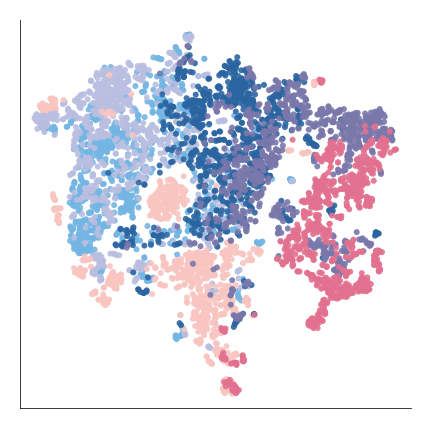

In [339]:
import importlib
import cvp_standardized as cvs
importlib.reload(cvs)

# PCA on z-scored features (all_dat is not modified)
pcs_z, evecs_z, evals_z, var_ratio_z = cvs.pca_standardized(all_dat)
print("variance explained, first 5 PCs:", (100 * var_ratio_z[:5]).round(1))

# t-SNE on z-scored features; rows line up with all_dat
tsne_z = cvs.tsne_standardized(all_dat, perplexity=50, random_state=28)

# condition-colored embedding
cvp.plot_tsne(
    input_dat=all_dat,
    exp_embedding=tsne_z,
    exp_colors=ytick_colors,
    n_fovs=n_fovs_2_analyze,
    dead_well_ids=dead_ids,
    figtitle="tsne_colored_by_experimental_condition_zscored",
    hide_in_cell=False,
)

# feature-colored embeddings
for feat_2_plot, feat_label in enumerate(training_feature_labels):
    safe = (feat_label.replace(" ", "_").replace("(", "").replace(")", "")
            .replace("/", "_").replace("-", "_").replace(",", "").lower())
    cvp.plot_tsne(
        input_dat=all_dat,
        exp_embedding=tsne_z,
        exp_colors=ytick_colors,
        n_fovs=n_fovs_2_analyze,
        dead_well_ids=dead_ids,
        figtitle=f"tsne_colored_by_{safe}_zscored",
        tsne_alpha=.9,
        feat_2_color_by=feat_2_plot,
        feat_cmap="apc:magma",
        feat_alpha=.7,
        hide_in_cell=True,
    )
    #feat_cmap="apc:verde",

In [340]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from scipy.stats import zscore

def plot_tsne_cbar(input_dat, exp_embedding, exp_colors, n_fovs, dead_well_ids, figtitle,
                   tsne_alpha=.9, feat_2_color_by=-1, feat_cmap="apc:verde", feat_alpha=.7,
                   hide_in_cell=True, cbar_label="", save_cbar_separately=True):
    dead = set(dead_well_ids)
    scatter_colors = [c for c in exp_colors for l in range(n_fovs*96) if l not in dead]
    emb = np.asarray(exp_embedding)

    fig, ax = plt.subplots(figsize=(7, 7))
    sc = None
    if feat_2_color_by < 0:
        ax.scatter(emb[:, 0], emb[:, 1], c=scatter_colors, alpha=tsne_alpha)
    else:
        feat_z = zscore(input_dat[:, feat_2_color_by])
        vmin, vmax = np.quantile(feat_z, [.01, .99])
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=feat_z, cmap=feat_cmap,
                        alpha=feat_alpha, vmin=vmin, vmax=vmax)
        # horizontal color bar above the plot, left-aligned like the pub figure
        cax = ax.inset_axes([0.0, 1.06, 0.6, 0.04])
        cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
        cbar.solids.set_alpha(1)
        cbar.set_label(cbar_label)
        cbar.ax.xaxis.set_label_position("top")

    ax.set_xticks([])
    ax.set_yticks([])
    base = "plots/chlorella_pub_fig_" + figtitle
    for ext in ("svg", "pdf", "png"):
        fig.savefig(f"{base}.{ext}", bbox_inches="tight")

    # standalone color bar file to drop into Illustrator
    if sc is not None and save_cbar_separately:
        cfig, cax2 = plt.subplots(figsize=(3.5, 0.25))
        cb2 = cfig.colorbar(ScalarMappable(norm=sc.norm, cmap=sc.cmap), cax=cax2,
                            orientation="horizontal")
        cb2.set_label(cbar_label)
        cb2.ax.xaxis.set_label_position("top")
        for ext in ("svg", "pdf", "png"):
            cfig.savefig(f"{base}_cbar.{ext}", bbox_inches="tight")
        plt.close(cfig)

    if hide_in_cell:
        plt.close(fig)
    else:
        plt.show()
    return None if sc is None else np.quantile(feat_z, .95)

for feat_2_plot, feat_label in enumerate(training_feature_labels):
    safe = (feat_label.replace(" ", "_").replace("(", "").replace(")", "")
            .replace("/", "_").replace("-", "_").replace(",", "").lower())
    plot_tsne_cbar(
        input_dat=all_dat,
        exp_embedding=tsne_z,
        exp_colors=ytick_colors,
        n_fovs=n_fovs_2_analyze,
        dead_well_ids=dead_ids,
        figtitle=f"tsne_colored_by_{safe}_zscored",
        feat_2_color_by=feat_2_plot,
        feat_cmap="apc:magma",
        feat_alpha=.7,
        cbar_label=f"{feat_label} (z-score)",
        hide_in_cell=True,   # set False to also see it in the notebook
    )

In [313]:
corr_df

,component,correlation
0,strain,0.880441
1,environment,0.467418
2,interaction,0.565144
3,residual,-0.943608


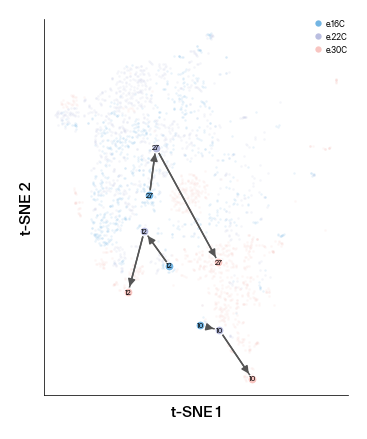

In [252]:
importlib.reload(cvs)

row_idx = cvs.tsne_row_index(exp_conditions, n_wells=96, n_fovs=n_fovs_2_analyze, dead_ids=dead_ids)

fig, ax, cent = cvs.plot_strain_tsne_trajectories(
    embedding=tsne_z,                  # or experiment_X_embedded for the raw-feature t-SNE
    row_index=row_idx,
    conditions=["e_stat_16", "e_stat_22", "e_stat_30"],
    strains_to_plot=[10, 12, 27],
    condition_colors=[apc.vital, apc.wish, apc.dress],
    condition_labels=["e.16C", "e.22C", "e.30C"],
    background="points",               # every field of view, faint, colored by condition
    figsize=(5, 6),
    save=True,
    figtitle="strain_10_12_27_tsne_trajectories",
)

In [253]:
import numpy as np, pandas as pd
importlib.reload(cvs)

mean_icc = np.nanmean(icc_results["icc_single"], axis=1)   # per feature, averaged over conditions

rows = []
for thr in [0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = np.where(mean_icc >= thr)[0]
    _, evecs_t, _, ratio_t = cvs.pca_standardized(all_dat[:, keep])
    labels_t = [training_feature_labels[i] for i in keep]
    top = lambda pc: ", ".join(pd.Series(np.abs(evecs_t[:, pc]), index=labels_t)
                               .sort_values(ascending=False).head(3).index)
    rows.append({"ICC ≥": thr, "n features": len(keep),
                 "PC1 %": round(100 * ratio_t[0], 1), "PC2 %": round(100 * ratio_t[1], 1),
                 "PC1 top": top(0), "PC2 top": top(1)})
pd.DataFrame(rows)

,ICC ≥,n features,PC1 %,PC2 %,PC1 top,PC2 top
0,0.5,32,51.3,16.8,"inertia_tensor-1-1 (bf), area (bf), inertia_te...","moments_hu-1 (cy5), moments_hu-0 (cy5), eccent..."
1,0.6,32,51.3,16.8,"inertia_tensor-1-1 (bf), area (bf), inertia_te...","moments_hu-1 (cy5), moments_hu-0 (cy5), eccent..."
2,0.7,30,54.7,17.7,"inertia_tensor-1-1 (bf), inertia_tensor_eigval...","moments_hu-0 (cy5), moments_hu-1 (cy5), eccent..."
3,0.8,27,59.8,15.5,"inertia_tensor_eigvals-0 (cy5), inertia_tensor...","solidity (bf), count (bf), count (cy5)"
4,0.9,24,66.5,16.1,"inertia_tensor_eigvals-0 (cy5), inertia_tensor...","solidity (bf), count (bf), count (cy5)"


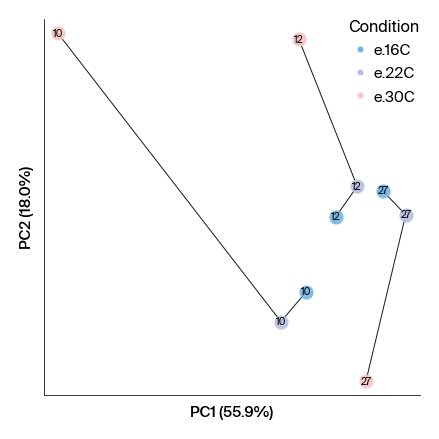

(<Figure size 432x432 with 1 Axes>,
 <Axes: xlabel='PC1 (55.9%)', ylabel='PC2 (18.0%)'>)

In [311]:
ICC_THRESHOLD = 0.5
reliable = np.where(mean_icc >= ICC_THRESHOLD)[0]
training_data_reliable = {c: training_data_finite[c][:, reliable] for c in training_data_finite}

cvs.plot_strain_pca_trajectories_standardized(
    training_data=training_data_reliable,
    exp_conditions=["e_stat_16", "e_stat_22", "e_stat_30"],
    pca_conditions=["e_stat_16", "e_stat_22", "e_stat_30"],
    strains_to_plot=[10, 12, 27],
    n_wells=96, 
    line_width=1,
    point_size=200,
    n_fovs=n_fovs_2_analyze, 
    dead_ids=dead_ids,
    condition_labels=["e.16C", "e.22C", "e.30C"],
    condition_colors=[apc.vital, apc.wish, apc.dress],
    fit_pca_on="all_strains",
    show_variance_explained=True, 
    show_title=False,
    figsize=(6, 6), save=True,
    figtitle=f"strain_10_12_27_pca_trajectories_icc{ICC_THRESHOLD}_zscored",
)

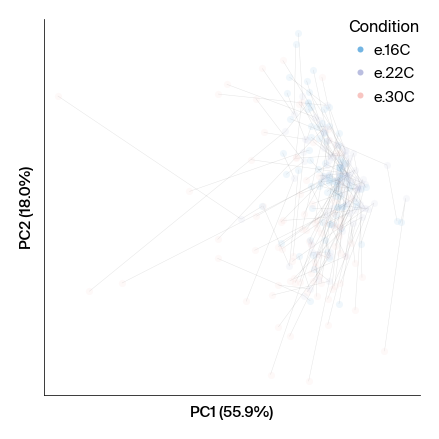

(<Figure size 432x432 with 1 Axes>,
 <Axes: xlabel='PC1 (55.9%)', ylabel='PC2 (18.0%)'>)

In [312]:
reload(cvp)

all_strains=list(range(96))
for n in dead_wells:
    all_strains.remove(n)

cvs.plot_strain_pca_trajectories_standardized(
    training_data=training_data_reliable,
    exp_conditions=["e_stat_16", "e_stat_22", "e_stat_30"],
    pca_conditions=["e_stat_16", "e_stat_22", "e_stat_30"],
    strains_to_plot=all_strains,
    n_wells=96, 
    point_size=50,
    alpha=.1,
    line_width=.5,
    annotate_points=False,
    n_fovs=n_fovs_2_analyze, 
    dead_ids=dead_ids,
    condition_labels=["e.16C", "e.22C", "e.30C"],
    condition_colors=[apc.vital, apc.wish, apc.dress],
    fit_pca_on="all_strains",
    show_variance_explained=True, 
    show_title=False,
    figsize=(6, 6), save=True,
    figtitle=f"all_strains_pca_trajectories_icc{ICC_THRESHOLD}_zscored",
)

In [256]:

'''
#temporarily try this
reload(cvp)
training_data_finite, hu_indices, hu_labels = cvp.signed_log_transform_hu_features(
    training_data_finite,
    training_feature_labels,
    log_base="log10",
    eps=1e-12,
    in_place=False,
)

'''

'\n#temporarily try this\nreload(cvp)\ntraining_data_finite, hu_indices, hu_labels = cvp.signed_log_transform_hu_features(\n    training_data_finite,\n    training_feature_labels,\n    log_base="log10",\n    eps=1e-12,\n    in_place=False,\n)\n\n'

In [314]:
dep_df

,strain,condition,obs_z,pred_z,sem_z,resid_z,z_emp,p_emp,p_perm,calib_slope,q
0,0,e_stat_16,-1.162025,-1.425594,0.182251,0.263568,0.611011,0.541192,0.218389,1.124993,0.983695
1,1,e_stat_16,-1.131578,-1.305833,0.173534,0.174255,0.434553,0.663887,0.417779,1.124993,0.983695
2,2,e_stat_16,-0.904020,-1.347139,0.141907,0.443119,0.965751,0.334169,0.041748,1.124993,0.931161
3,3,e_stat_16,-0.993540,-1.380179,0.183151,0.386639,0.854163,0.393015,0.074496,1.124993,0.970978
4,4,e_stat_16,-0.353421,-0.972044,0.142454,0.618623,1.312495,0.189353,0.004900,1.124993,0.851742
...,...,...,...,...,...,...,...,...,...,...,...
541,91,l_stat_30,1.719389,1.903943,0.052005,-0.184554,-0.303501,0.761508,0.373981,1.629073,0.984371
542,92,l_stat_30,1.553260,1.691907,0.049263,-0.138648,-0.214017,0.830534,0.503525,1.629073,0.987940
543,93,l_stat_30,1.736462,1.977183,0.039549,-0.240721,-0.412984,0.679618,0.247088,1.629073,0.983695
544,94,l_stat_30,-2.108947,-2.088033,0.068239,-0.020914,0.015478,0.987651,0.920754,1.629073,1.000000


In [259]:
# example: train a ridge model to predict phenotypes in one condition given the other conditions

train_conditions = ["e_stat_22", "e_stat_30", "l_stat_16", "l_stat_22","l_stat_30"]
test_condition = "e_stat_16"

y_pred, metrics, model = cvp.train_and_predict(
    training_data_finite,
    train_conditions,
    test_condition,
    model_type="ridge",
    alpha=3000 #higher (10,100) alpha is more robust to unseen data, lower (.1, .01) alpha is a better fit to the data
)

#metrics show the rsqared values for each feature
print(metrics["r2_overall"])

0.4610595230664254


In [258]:
#quick alpha scan for ridge regression model

mean_rs2=[]
as_2_try = []
a = 1 #start
a_res = 16 #datapoints to try
for i in range(a_res):
    a = a * 2
    as_2_try.append(int(a))

for a in as_2_try:
    comparison_results = cvp.compare_models_condition_holdout_cv(
        #training_data=training_data_finite,
        training_data=training_data_finite,
        exp_conditions=exp_conditions,
        ridge_alpha=a,
        n_splits=16
    )
    
    #mean_r2 = np.mean(comparison_results["ridge"]["overall_r2"])
    mean_r2=np.mean(np.median(comparison_results["ridge"]['r2_per_feature'],axis=1))
    mean_rs2.append(comparison_results["ridge"]["overall_r2"])
    print(a, mean_r2)

2 0.1926432780162902
4 0.22394817575019602
8 0.282449552236185
16 0.3330922361685859
32 0.36714657670635004
64 0.39230062361553686
128 0.4144409532622813
256 0.4400569222875172
512 0.47898228307892327
1024 0.5024269979201176
2048 0.5096043345328
4096 0.4978154364576586
8192 0.46751664300257706
16384 0.4015580608686446
32768 0.31361895904374176
65536 0.22063373847730797


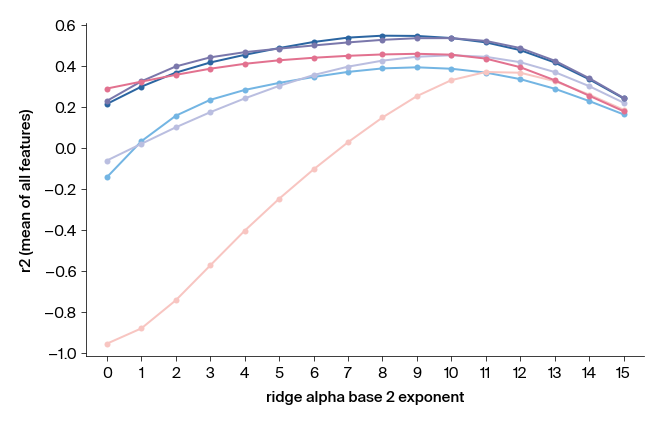

In [260]:
as_strings=[]
for a in range(len(as_2_try)):
    #as_strings.append(str(a))
    as_strings.append(str(a))

c_strings=["apc:vital","apc:wish","apc:dress","apc:lapis","apc:aster","apc:candy"]
fig,ax=plt.subplots()
fig.set_size_inches(10,6)
ax.set_xticks(range(len(as_2_try)))
ax.set_xticklabels(as_strings)
for i in range(6):
     plt.plot(np.array(mean_rs2).T[i],c=c_strings[i],marker='o')
plt.xlabel("ridge alpha base 2 exponent")
plt.ylabel("r2 (mean of all features)")

plt.show()
fig.savefig('plots/alpha_scan_conditional_cross_validated_holdout_16split.svg')
fig.savefig('plots/alpha_scan_conditional_cross_validated_holdout_16split.png')
fig.savefig('plots/alpha_scan_conditional_cross_validated_holdout_16split.pdf')



In [261]:
 comparison_results = cvp.compare_models_condition_holdout_cv(
        #training_data=training_data_finite,
        training_data=training_data_finite,
        exp_conditions=exp_conditions,
        ridge_alpha=3000,
        n_splits=16)

In [262]:
'''
# Evaluating Model Performance 

# number of usable rows per condition after removing dead_ids
n_rows_per_condition = training_data_finite[exp_conditions[0]].shape[0] - len(dead_ids)

r, p = cvp.cross_validation_and_alpha_scan(
    #training_dat=training_data_finite,
    training_dat=training_data_hu_log,
    exp_colors=ytick_colors,
    exp_labels=exp_conditions,
    fig_size=(10, 5),
    alphas_2_try=as_2_try,
    tv_splits=16,
    n_permuts=100,
    rand_state=42
)  
'''

'\n# Evaluating Model Performance \n\n# number of usable rows per condition after removing dead_ids\nn_rows_per_condition = training_data_finite[exp_conditions[0]].shape[0] - len(dead_ids)\n\nr, p = cvp.cross_validation_and_alpha_scan(\n    #training_dat=training_data_finite,\n    training_dat=training_data_hu_log,\n    exp_colors=ytick_colors,\n    exp_labels=exp_conditions,\n    fig_size=(10, 5),\n    alphas_2_try=as_2_try,\n    tv_splits=16,\n    n_permuts=100,\n    rand_state=42\n)  \n'

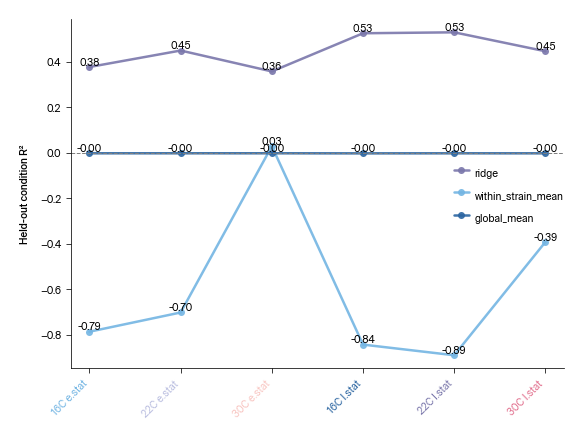

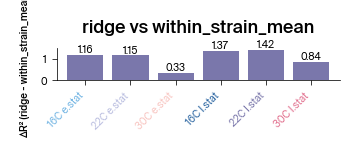

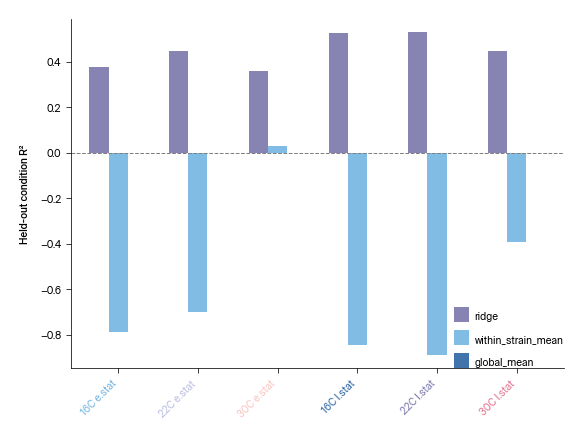

In [263]:
reload(cvp)

comparison_results = cvp.compare_models_condition_holdout_cv(
    #training_data=training_data_finite,
    training_data=training_data_finite,
    exp_conditions=exp_conditions,
    ridge_alpha=3000,
    n_splits=16,
    random_state=42,
    include_global_mean=True,
    include_within_strain_mean=True
)

fig, ax, plot_df = cvp.plot_condition_holdout_model_comparison(
    comparison_results=comparison_results,
    model_order=("ridge", "within_strain_mean", "global_mean"),
    metric="overall_r2",
    col_titles=['16C e.stat', '22C e.stat', '30C e.stat',
                '16C l.stat', '22C l.stat', '30C l.stat'],
    xtick_colors=[apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy],
    plot_mode="line",
    figsize=(8, 6),
    show_values=True,
    save=True,
    show_title=False,
    figtitle="condition_holdout_model_comparison_r2"
)

fig, ax, delta = cvp.plot_model_delta_overall(
    comparison_results,
    model_a="ridge",
    model_b="within_strain_mean",
    metric="overall_r2",
    col_titles=['16C e.stat', '22C e.stat', '30C e.stat',
                '16C l.stat', '22C l.stat', '30C l.stat'],
    xtick_colors=[apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy],
    show_values=True,
    figsize=(5, 2),
    save=True,
    figtitle="ridge_minus_within_strain_mean_delta_r2"
)
fig, ax, plot_df = cvp.plot_condition_holdout_model_comparison(
    comparison_results=comparison_results,
    model_order=("ridge", "within_strain_mean", "global_mean"),
    metric="overall_r2",
    col_titles=['16C e.stat', '22C e.stat', '30C e.stat',
                '16C l.stat', '22C l.stat', '30C l.stat'],
    xtick_colors=[apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy],
    plot_mode="bar",
    figsize=(8, 6),
    show_values=False,
    show_title=False,
    save=True,
    figtitle="condition_holdout_model_comparison_r2_bar"
)

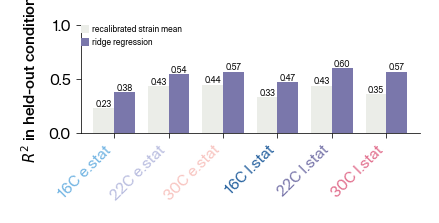

model      ridge  strain_mean_recal    gap
condition                                 
e_stat_16  0.375              0.225  0.150
e_stat_22  0.545              0.433  0.112
e_stat_30  0.567              0.444  0.123
l_stat_16  0.468              0.330  0.138
l_stat_22  0.599              0.434  0.165
l_stat_30  0.567              0.353  0.213


In [301]:
import importlib
import cvp_baseline_additions as cba
importlib.reload(cba)

well_groups = cba.well_groups(96, n_fovs_2_analyze)
keep = np.setdiff1d(np.arange(96 * n_fovs_2_analyze), np.asarray(dead_ids, dtype=int))
baseline_input = {c: training_data_finite[c][keep] for c in exp_conditions}

recal_results = cba.compare_models_condition_holdout_cv_recalibrated(
    baseline_input,
    exp_conditions=exp_conditions,
    ridge_alpha=3000,              # match the schematic and methods
    n_splits=16,
    groups=well_groups[keep],      # grouped by well, as the schematic says
)

col_titles = ['16C e.stat', '22C e.stat', '30C e.stat',
              '16C l.stat', '22C l.stat', '30C l.stat']
xtick_colors = [apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy]

fig, ax, r2_df = cba.plot_ridge_vs_recalibrated_r2(
    recal_results,
    col_titles=col_titles,
    xtick_colors=xtick_colors,
    save=True,
)

# numbers for the text
print(r2_df.pivot(index="condition", columns="model", values="value")
      .assign(gap=lambda d: d["ridge"] - d["strain_mean_recal"]).round(3))

In [264]:
ridge_model_res = cvp.condition_holdout_permutation_test(
    #training_data_finite,
    training_data_finite,
    alpha=3000,
    n_splits=16,
    n_permutations=50, #5 for testing code, 200 for enough permutations (this will take 30 min to an hour on most CPUs) , 1000 if you can afford it
    random_state=42
)

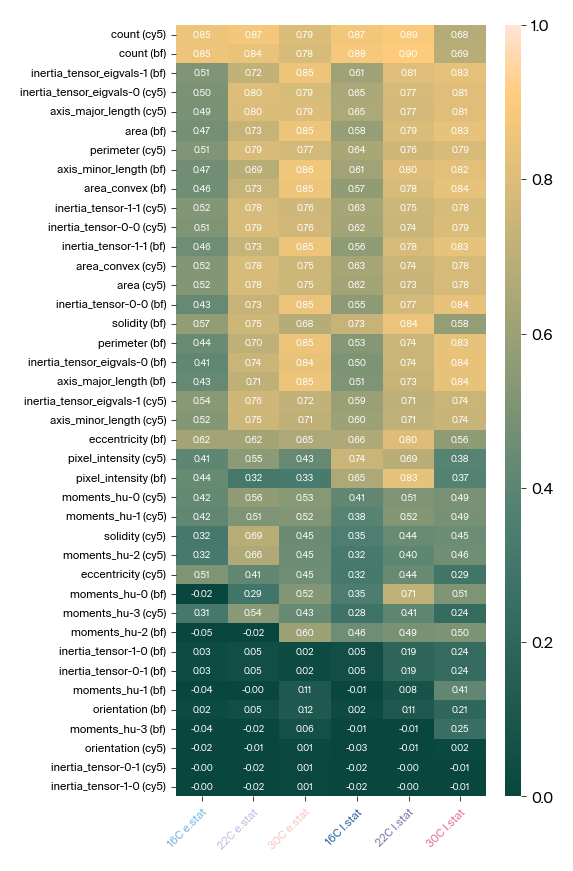

In [265]:
reload(cvp)

fig, ax, sorted_df = cvp.plot_sorted_r2_per_feature(
    ridge_model_residulals={"real": {"r2_per_feature": recal_results["ridge"]["r2_per_feature"]},
                            "conditions": exp_conditions},
    training_feature_labels=training_feature_labels,
    xtick_colors=[apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy],
    x_tick_rotation=45,
    col_titles=['16C e.stat', '22C e.stat', '30C e.stat', '16C l.stat', '22C l.stat', '30C l.stat'],
    figsize=(8, 12),
    font_size=11,
    annot=True,
    annot_fontsize=9,
    annot_color="white",
    cbar=True,
    cbar_shrink=1,
    cbar_aspect=50,
    orientation="horizontal",
    save=True
)

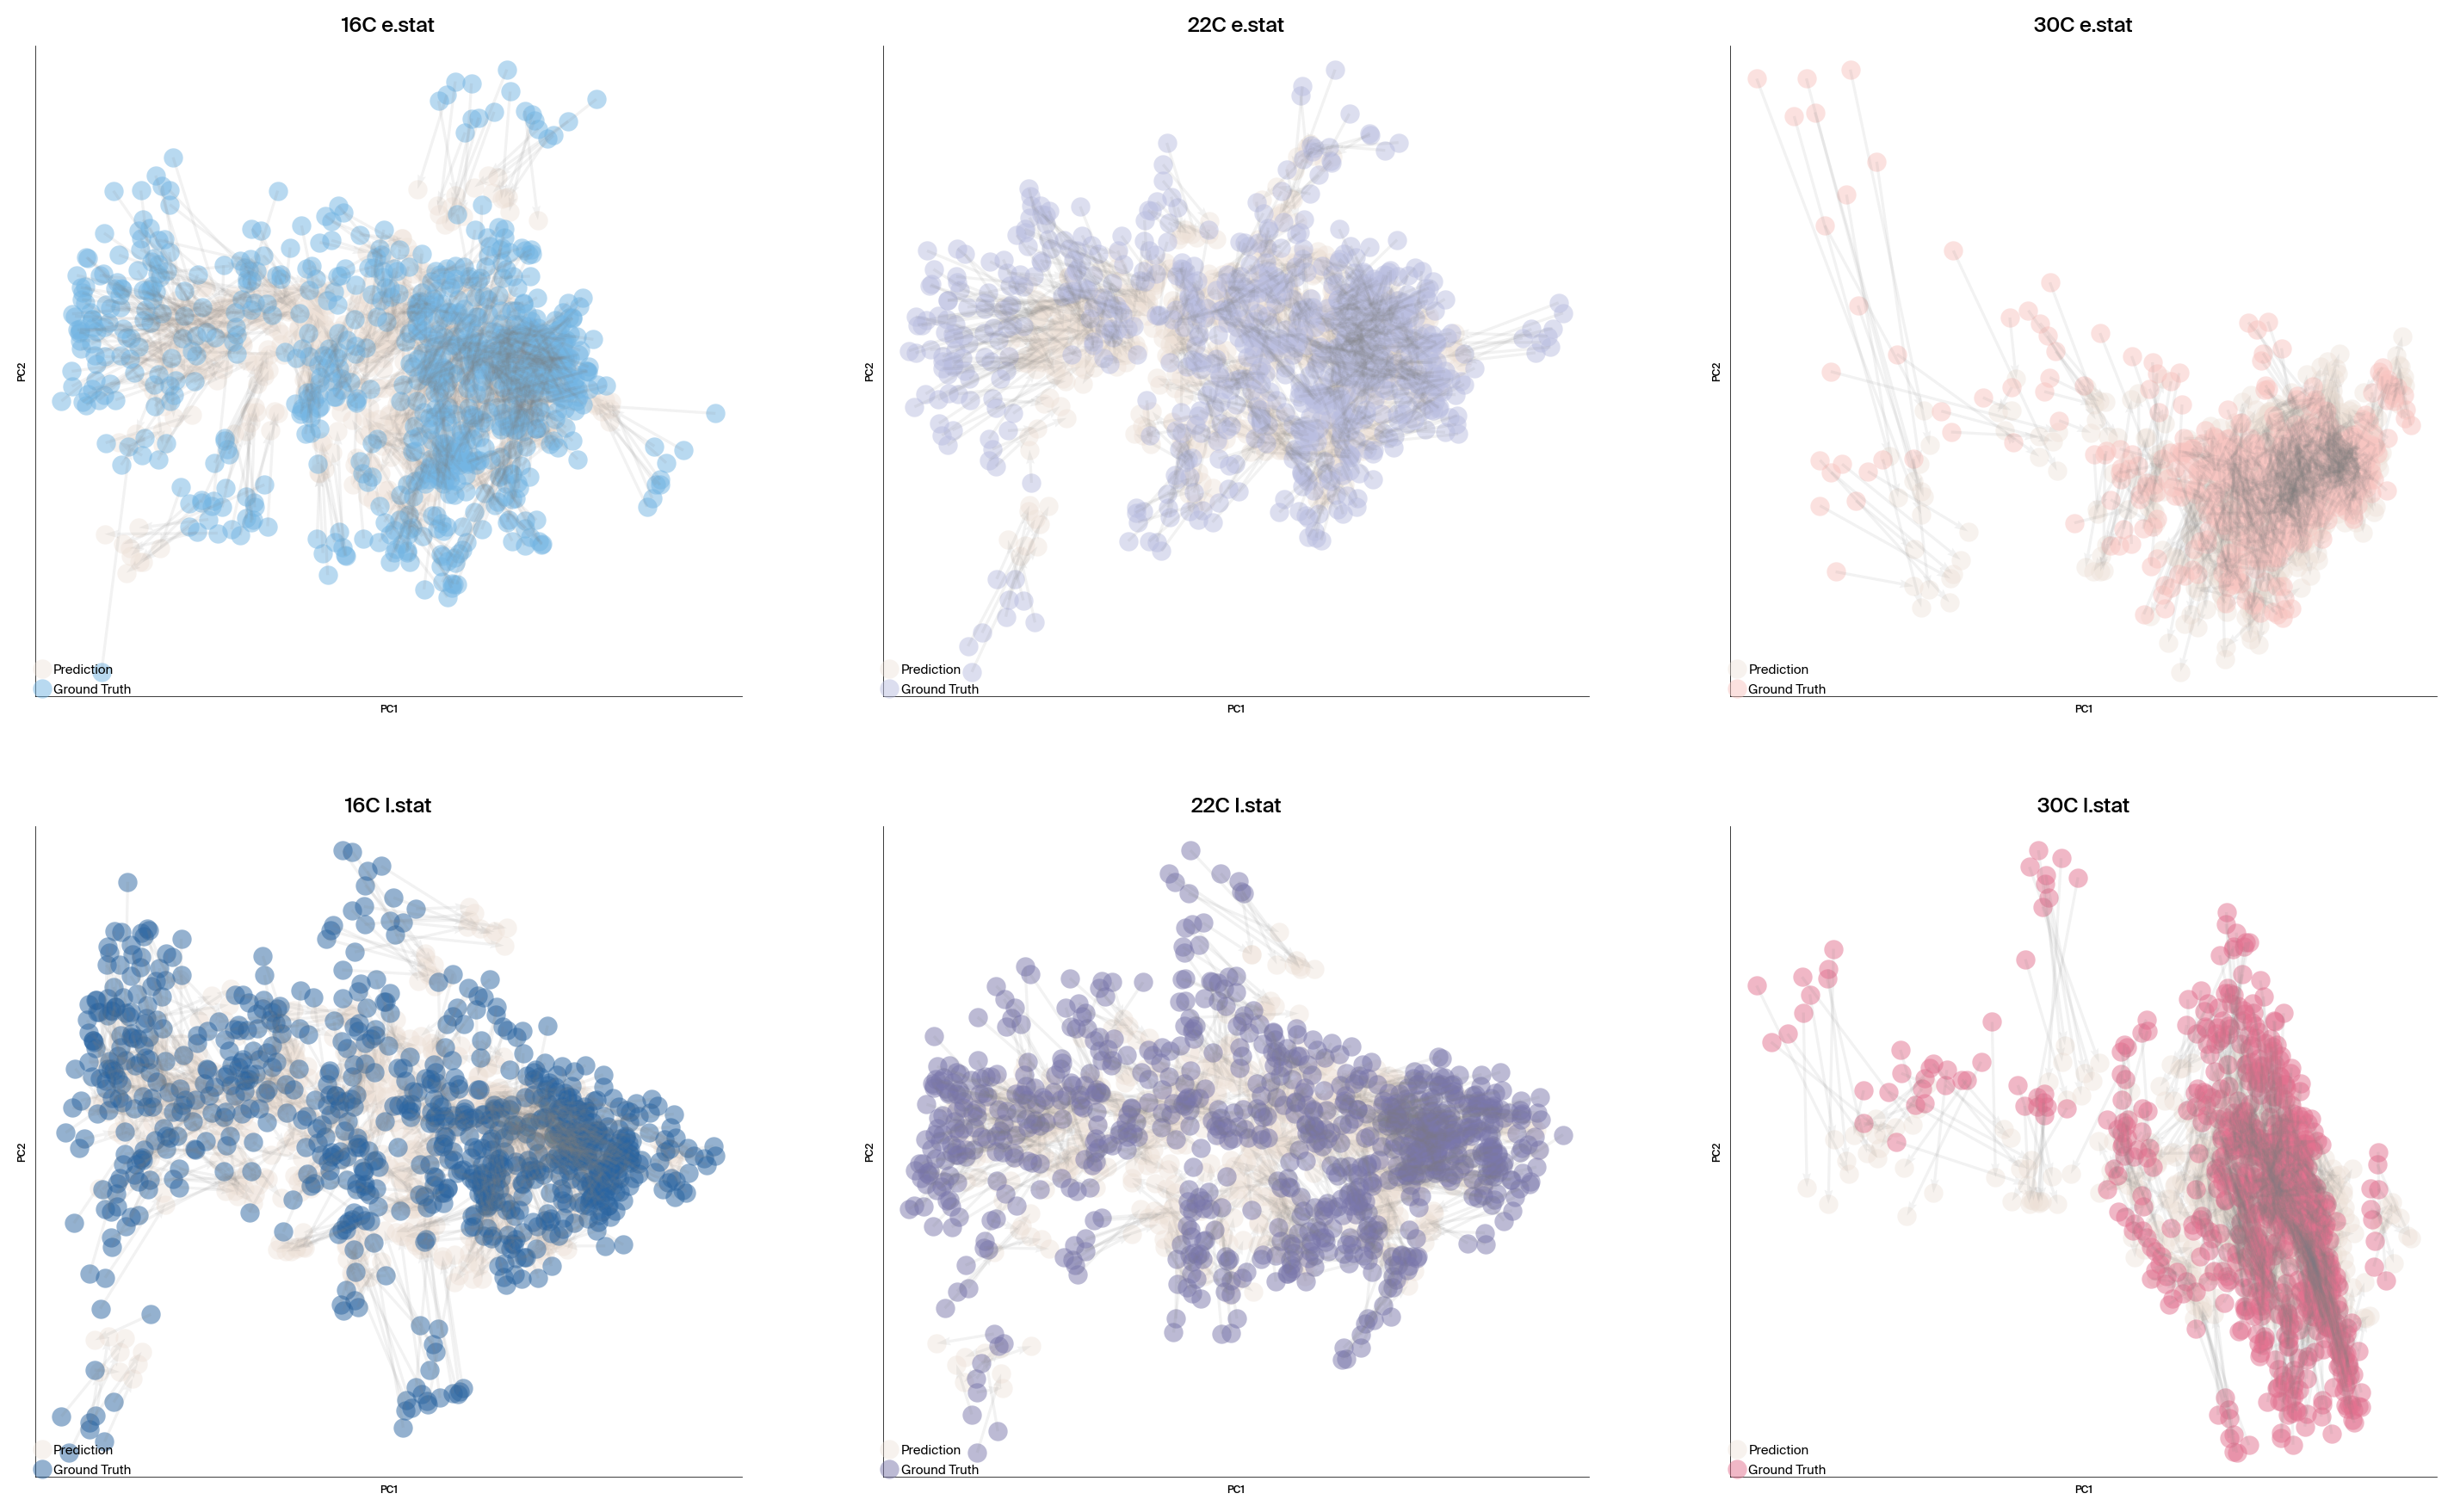

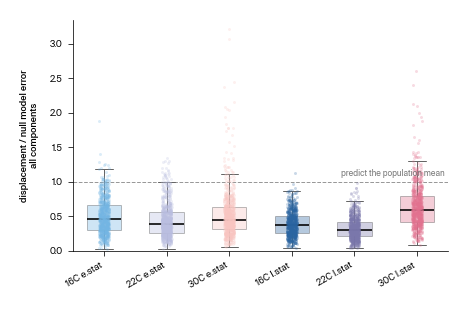

condition
e_stat_16    0.460795
e_stat_22    0.387483
e_stat_30    0.450024
l_stat_16    0.374456
l_stat_22    0.302538
l_stat_30    0.591512
Name: displacement, dtype: float64

In [303]:
reload(cba)

fig, ax, data_for_PCA_graphs = cvp.plot_true_vs_predicted_pca_by_condition(
    training_data=training_data_finite,
    exp_conditions=["e_stat_16", "e_stat_22", "e_stat_30", "l_stat_16", "l_stat_22", "l_stat_30"],
    dead_ids=dead_ids,
    ytick_colors=ytick_colors,
    col_titles=col_titles,
    marker_size=500,
    alpha=3000,
    prediction_alpha=.4,
    ground_truth_alpha=.5,
    quiver_width=.004,
    quiver_alpha=.1,
    figsize=(50, 30),
    save=True
)

fig, ax, disp = cba.plot_prediction_displacements(
    data_for_PCA_graphs, 
    exp_conditions,
    col_titles=col_titles, 
    condition_colors=ytick_colors,
    n_components=None, 
    normalize=True,
    save=True, 
    figtitle="prediction_displacement_distributions",
)

disp.groupby("condition").displacement.median()

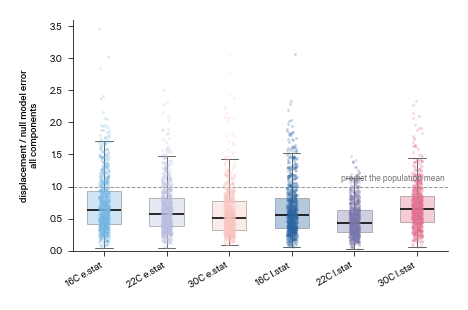

condition
e_stat_16    0.629645
e_stat_22    0.579239
e_stat_30    0.511867
l_stat_16    0.550132
l_stat_22    0.429532
l_stat_30    0.646502
Name: displacement, dtype: float64

In [300]:
reload(cba)
well_groups = cba.well_groups(96, n_fovs_2_analyze)

# grouped, out-of-fold ridge predictions (same as the calibration panel)
oof = cba._oof_by_condition(
    training_data_finite, exp_conditions,
    ridge_alpha=3000, n_splits=16, groups=well_groups, random_state=42,
)

# drop dead wells, z-score each feature within condition (using observed mean/SD)
row_well = np.arange(96 * n_fovs_2_analyze) % 96
dead_wells = sorted({int(d) % 96 for d in dead_ids})
live = ~np.isin(row_well, dead_wells)

disp_input = []
for cond in exp_conditions:
    obs, pred = oof[cond]
    obs, pred = obs[live], pred[live]
    mu, sd = obs.mean(axis=0), obs.std(axis=0)
    sd[sd == 0] = 1.0
    disp_input.append([(obs - mu) / sd, (pred - mu) / sd])

fig, ax, disp = cba.plot_prediction_displacements(
    disp_input,
    exp_conditions,
    col_titles=col_titles,
    condition_colors=ytick_colors,
    n_components=5,       # all features, i.e. full distance
    normalize=True,          # divide by the "predict the population mean" error
    save=True,
    figtitle="prediction_displacement_distributions_oof_zscored",
)

disp.groupby("condition").displacement.median()

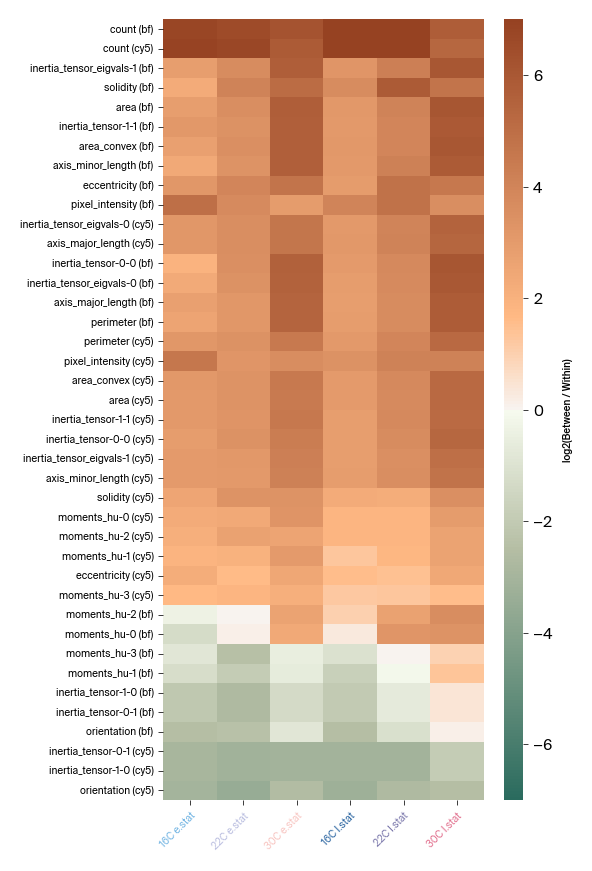

In [267]:
reload(cvp)
ratio_mat, ratio_conditions = cvp.compute_within_between_ratio_matrix(
    #training_data=training_data_finite,
    training_data=training_data_finite,
    condition_order=exp_conditions,
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    log2_transform=True
)

fig, ax, plot_df = cvp.plot_within_between_ratio_heatmap(
    ratio_mat=ratio_mat,
    training_feature_labels=training_feature_labels,
    condition_order=ratio_conditions,
    col_titles=['16C e.stat', '22C e.stat', '30C e.stat',
                '16C l.stat', '22C l.stat', '30C l.stat'],
    orientation="vertical",
    xtick_colors=[apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy],
    sort_features=True,
    figsize=(8, 12),
    show_title=False,
    cbar_shrink=1,
    cbar_aspect=40,
    save=True,
    vmax=7,
    vmin=-7
)

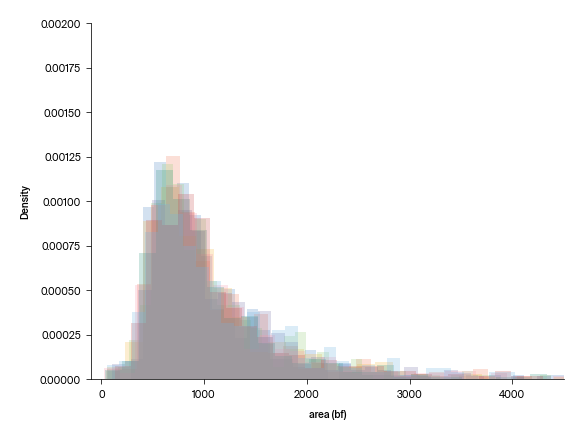

In [268]:
reload(cvp)

fig, ax, feature_data_by_fov = cvp.plot_feature_distribution_across_fovs(
    zroots,
    experiment=2,
    well=56,
    feature="area",
    channel="BF",
    n_fovs=n_fovs_2_analyze,
    bins=40,
    use_density=True,
    show_title=False,
    legend=False,
    figsize=(8,6),
    alpha=0.25,
    save=True,
    xlim=[-100,4500],
    ylim=[0,.002]
)

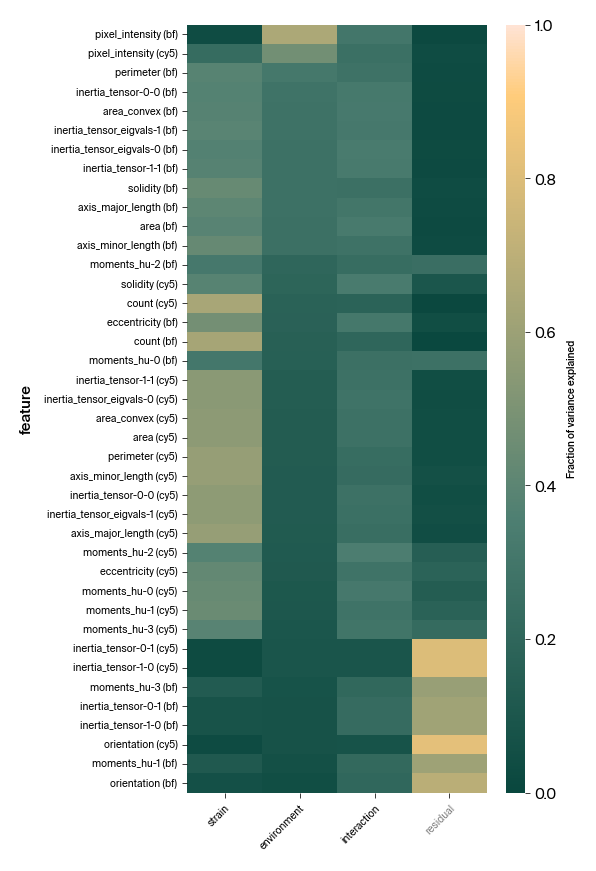

In [269]:
reload(cvp)

variance_df = cvp.compute_variance_partitioning_by_feature(
    #training_data=training_data_finite,
    training_data=training_data_finite,
    training_feature_labels=training_feature_labels,
    condition_order=exp_conditions,
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids
)


fig, ax, plot_df = cvp.plot_variance_partitioning_heatmap(
    variance_df,
    orientation="horizontal",
    sort_features=True,
    sort_by="environment",
    show_title=False,
    figsize=(8, 12),
    xtick_colors=["black", "black", "black", "grey"],  # if vertical: x-axis is components, so probably leave None
    cbar_shrink=1,
    cbar_aspect=40,
    save=True,
    cmap="apc:verde"
)

/Users/rockwell/repos/2026-chlorella-phenotyping/cvp.py:3563: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



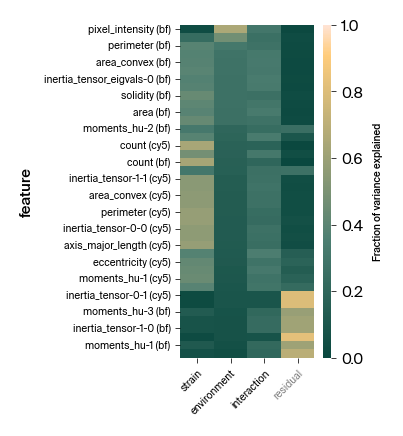

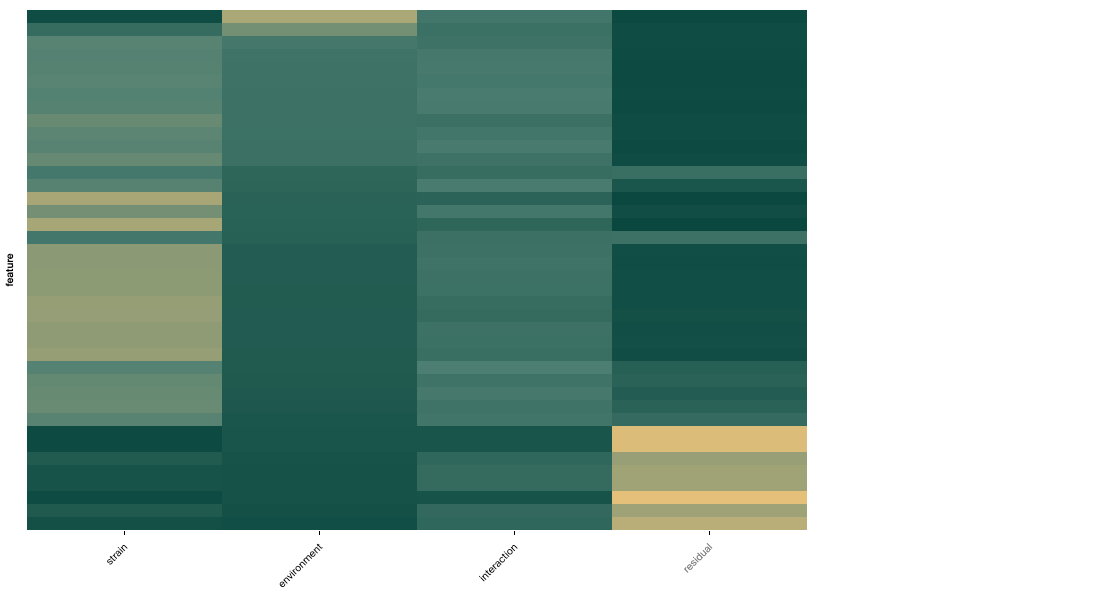

In [304]:
reload(cvp)
reload(cba)


# optional: add each feature's mean ridge R² so it shows up on hover
mean_r2 = dict(zip(training_feature_labels,
                   np.nanmean(recal_results["ridge"]["r2_per_feature"], axis=0)))
variance_df["mean_ridge_r2"] = variance_df["feature"].map(mean_r2)

show_labels = True    # False hides tick labels and axis titles in the Plotly figure

fig, ax, plot_df, var_pfig = cba.plot_variance_partitioning_heatmap(
    variance_df,
    orientation="horizontal",
    sort_features=True,
    sort_by="environment",
    show_title=False,
    figsize=(3, 6),
    xtick_colors=["black", "black", "black", "grey"],
    cbar_shrink=1,
    cbar_aspect=40,
    save=True,
    cmap="apc:verde",

    # --- Plotly version ---
    backend="both",
    hover_fields=["feature", "component", "value"],
    plotly_show_xticklabels=show_labels,
    plotly_show_yticklabels=False,
    plotly_layout={} if show_labels else {"xaxis_title_text": "", "yaxis_title_text": ""},
    plotly_cbar=False,
)

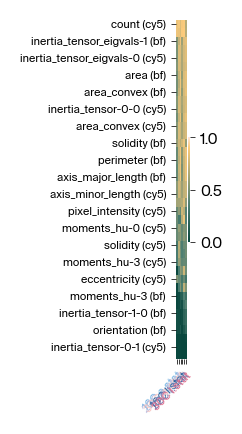

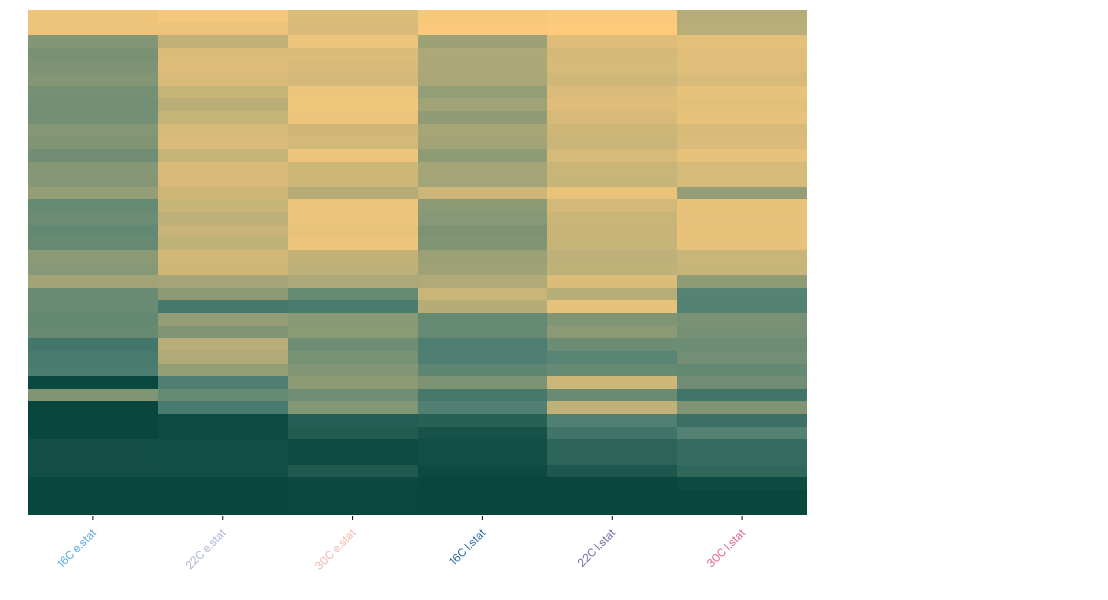

In [305]:
reload(cvp)
reload(cba)

show_labels = False    # False hides tick labels and axis titles in the Plotly figure

fig, ax, sorted_df, r2_pfig = cba.plot_sorted_r2_per_feature(
    ridge_model_residulals={"real": {"r2_per_feature": recal_results["ridge"]["r2_per_feature"],
                                     "r2_overall": recal_results["ridge"]["overall_r2"]},
                            "conditions": exp_conditions},
    training_feature_labels=training_feature_labels,
    xtick_colors=[apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy],
    x_tick_rotation=45,
    col_titles=['16C e.stat', '22C e.stat', '30C e.stat', '16C l.stat', '22C l.stat', '30C l.stat'],
    figsize=(3, 6),
    font_size=11,
    annot=False,
    annot_fontsize=9,
    annot_color="white",
    cbar=True,
    cbar_shrink=1,
    cbar_aspect=50,
    orientation="horizontal",
    save=True,

    # --- Plotly version ---
    backend="both",                            # "plotly" for the interactive one only
    hover_fields=["feature", "condition", "value"],
    plotly_show_xticklabels=True,
    plotly_show_yticklabels=show_labels,
    plotly_layout={} if show_labels else {"xaxis_title_text": "", "yaxis_title_text": ""},
    plotly_cbar=False,
)

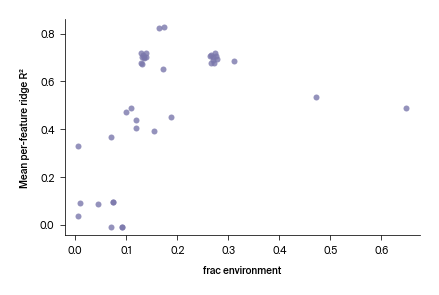

In [36]:
reload(cvp)

merged_df = cvp.merge_variance_and_ridge_results(
    variance_df=variance_df,
    comparison_results=recal_results,
    training_feature_labels=training_feature_labels,
    model_name="ridge"
)
fig, ax = cvp.plot_ridge_vs_variance_component(
    merged_df,
    component="frac_environment",
    figsize=(6, 4),
    save=True,
    show_title=False,
    figtitle="ridge_vs_environment_fraction"
)

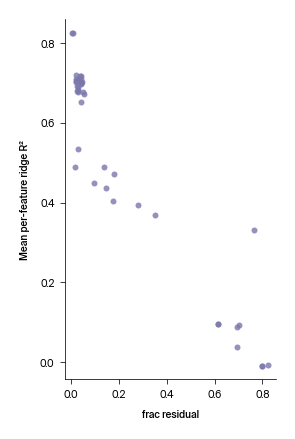

In [319]:
fig, ax = cvp.plot_ridge_vs_variance_component(
    merged_df,
    component="frac_residual",
    figsize=(4, 6),
    save=True,
    show_title=False,
    figtitle="ridge_vs_residual_fraction_long"
)

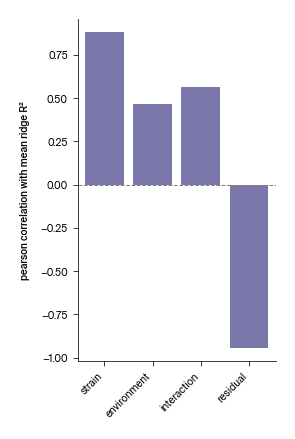

In [320]:
fig, ax, corr_df = cvp.plot_ridge_variance_component_correlations(
    merged_df,
    method="pearson",
    figsize=(4, 6),
    save=True,
    show_title=False,
    figtitle="ridge_vs_variance_component_correlations_long"
)

In [325]:
corr_df

,component,correlation
0,strain,0.880441
1,environment,0.467418
2,interaction,0.565144
3,residual,-0.943608


In [273]:
import importlib
import cvp_baseline_additions as cba
importlib.reload(cba)

# rows are well-field pairs: 96 wells x 9 FoVs, in well-major order
well_groups = cba.well_groups(96, n_fovs_2_analyze)

# optional: drop the wells that never grew, so imputed rows don't drag the comparison
EXCLUDE_DEAD = True
if EXCLUDE_DEAD:
    keep = np.setdiff1d(np.arange(96 * n_fovs_2_analyze), np.asarray(dead_ids, dtype=int))
    baseline_input = {c: training_data_finite[c][keep] for c in exp_conditions}
    baseline_groups = well_groups[keep]
else:
    baseline_input = training_data_finite
    baseline_groups = well_groups

recal_results = cba.compare_models_condition_holdout_cv_recalibrated(
    baseline_input,
    exp_conditions=exp_conditions,
    ridge_alpha=3000,          # must match the alpha used for comparison_results
    n_splits=16,
    groups=baseline_groups,   # set to None to reproduce the ungrouped numbers
)

capture_df = cba.summarize_interaction_capture(recal_results, training_feature_labels)

for m in ("ridge", "strain_mean_recal", "strain_mean", "global_mean"):
    print(f"{m:<20} mean overall R2 = {np.mean(recal_results[m]['overall_r2']):+.3f}")
print(f"\ninteraction captured (ridge - recalibrated baseline): "
      f"{capture_df['interaction_captured'].mean():+.3f}")


ridge                mean overall R2 = +0.520
strain_mean_recal    mean overall R2 = +0.370
strain_mean          mean overall R2 = -0.411
global_mean          mean overall R2 = -0.010

interaction captured (ridge - recalibrated baseline): +0.150


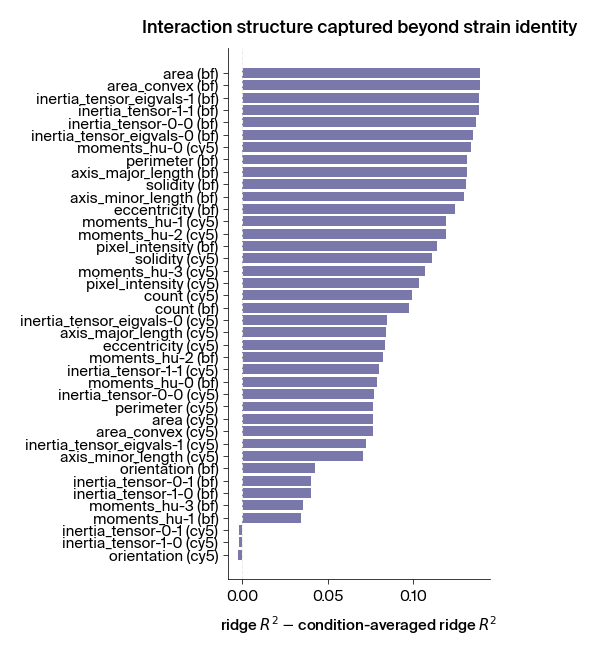

                      frac_strain  frac_interaction  interaction_captured
frac_strain              1.000000          0.433967              0.058377
frac_interaction         0.433967          1.000000              0.713703
interaction_captured     0.058377          0.713703              1.000000


In [274]:
fig, ax = cba.plot_interaction_capture(
    capture_df,
    figsize=(7, 9),
    save=True,
    figtitle="interaction_capture_vs_recalibrated_baseline",
)

# join onto the variance fractions to ask what predicts the captured interaction
capture_vs_variance = variance_df.merge(
    capture_df[["feature", "r2_ridge", "r2_strain_mean_recal",
                "interaction_captured", "recalibration_gain"]],
    on="feature", how="inner",
)

print(capture_vs_variance[["frac_strain", "frac_interaction",
                           "interaction_captured"]].corr(method="pearson"))

In [275]:
apparent   = capture_df["r2_ridge"] - capture_df["r2_strain_mean"]        # the cell 35 delta
real       = capture_df["interaction_captured"]                          # ridge - recalibrated
recal_frac = capture_df["recalibration_gain"] / apparent

print(f"apparent advantage (current figure):  {apparent.mean():+.3f}")
print(f"of which recalibration:               {capture_df['recalibration_gain'].mean():+.3f}")
print(f"of which real:                        {real.mean():+.3f}")
print(f"share that is recalibration:          {recal_frac.mean():.1%}")

apparent advantage (current figure):  +0.931
of which recalibration:               +0.781
of which real:                        +0.150
share that is recalibration:          79.6%


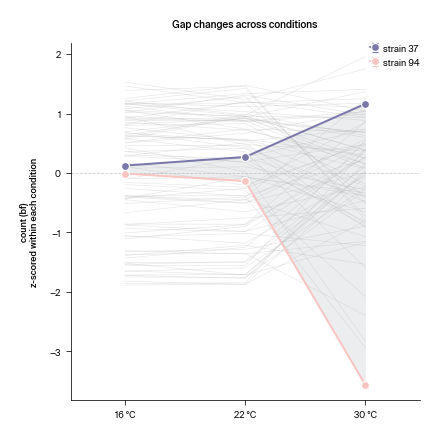

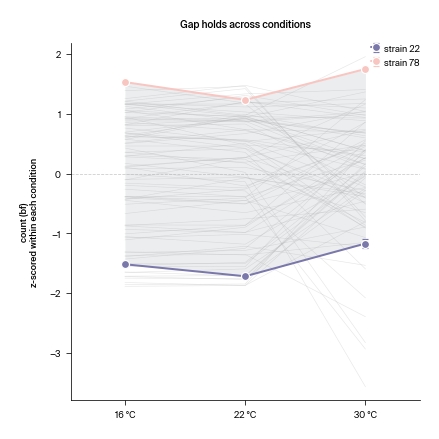

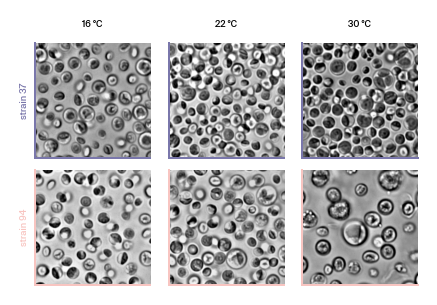

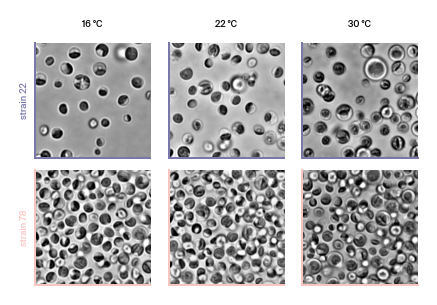

(<Figure size 432x295.2 with 6 Axes>,
 array([[<Axes: title={'center': '16 °C'}, ylabel='strain 22'>,
         <Axes: title={'center': '22 °C'}>,
         <Axes: title={'center': '30 °C'}>],
        [<Axes: ylabel='strain 78'>, <Axes: >, <Axes: >]], dtype=object))

In [276]:
importlib.reload(cba)

early = ["l_stat_16", "l_stat_22", "l_stat_30"]
rnorm_exp_ids=[0, 1, 2]
rnorm_labels = ["16 °C", "22 °C","30 °C"]
#rnorm_feature="count (bf)"
rnorm_feature="count (bf)"
#rnorm_feature="area (bf)"
rnorm_channel="bf"
rnorm_crop=300
rnorm_fov=0
rnorm_iloc_sub=0

pairs = cba.find_interaction_example_strains(
    training_data_finite, 
    training_feature_labels,
    feature=rnorm_feature,          # visible by eye, use-verdict, interaction 0.27
    conditions=early,
    n_wells=96, 
    n_fovs=n_fovs_2_analyze, 
    dead_ids=dead_ids,
    apart_min=1, 
    together_max=0.2, 
    min_snr=3,
)
pairs[["kind", "strain_a", "strain_b", "min_abs_gap", "max_abs_gap",
       "gap_change_snr", "closest_condition", "farthest_condition"]]


for kind, title, tag in [
    ("interaction", "Gap changes across conditions", "reaction_norm_interaction"),
    ("strain",      "Gap holds across conditions",   "reaction_norm_strain_identity"),
]:
    subset = pairs[pairs.kind == kind]
    if subset.empty:
        print(f"no {kind} pairs — loosen the thresholds")
        continue
    row = subset.iloc[rnorm_iloc_sub]
    cba.plot_strain_pair_reaction_norm(
        training_data_finite, 
        training_feature_labels,
        feature=rnorm_feature, 
        conditions=early,
        strain_a=int(row.strain_a), 
        strain_b=int(row.strain_b),
        condition_labels=rnorm_labels,
        n_wells=96, 
        figsize=(6,6),
        n_fovs=n_fovs_2_analyze, 
        dead_ids=dead_ids,
        title=title, 
        save=True, 
        figtitle=tag,
        show_population=True,
        annotate_gaps=True,
    )


row = pairs[pairs.kind == "interaction"].iloc[rnorm_iloc_sub]
cba.plot_strain_pair_cell_grid(
    zroots,
    strain_a=int(row.strain_a), 
    strain_b=int(row.strain_b),
    experiment_indices=rnorm_exp_ids,
    condition_labels=rnorm_labels,
    channel=rnorm_channel, 
    fov=rnorm_fov, 
    n_cells=1, 
    crop=rnorm_crop,
    um_per_pixel=None,          # set it and you get a scale bar
    save=True, figtitle="interaction_example_cells",
)

row = pairs[pairs.kind == "strain"].iloc[rnorm_iloc_sub]
cba.plot_strain_pair_cell_grid(
    zroots,
    strain_a=int(row.strain_a), 
    strain_b=int(row.strain_b),
    experiment_indices=rnorm_exp_ids,
    condition_labels=rnorm_labels,
    channel=rnorm_channel, 
    fov=rnorm_fov, 
    n_cells=1, 
    crop=rnorm_crop,
    um_per_pixel=None,          # set it and you get a scale bar
    save=True, figtitle="strain_example_cells",
)



/Users/rockwell/repos/2026-chlorella-phenotyping/cvp_departures.py:296: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



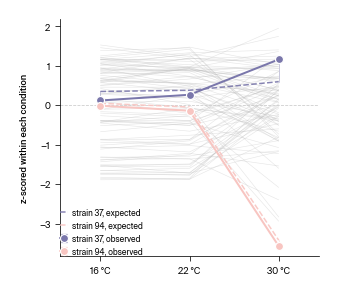

/Users/rockwell/repos/2026-chlorella-phenotyping/cvp_departures.py:296: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



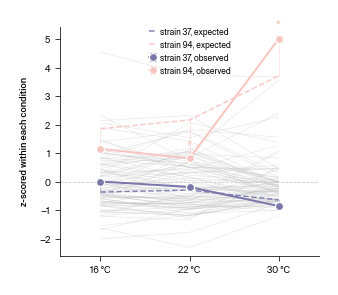

/Users/rockwell/repos/2026-chlorella-phenotyping/cvp_departures.py:296: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



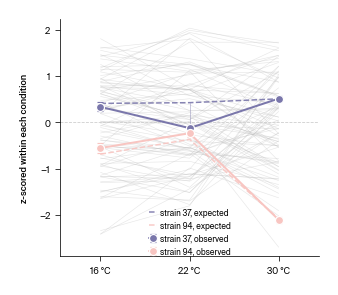

In [290]:
import importlib
import cvp_departures as cdp
importlib.reload(cdp)

dep_df = cdp.compute_strain_departures(
    training_data_finite,          # full arrays; dead wells dropped via dead_ids
    exp_conditions,                # all 6, the model uses them all as predictors
    training_feature_labels,
    #feature="solidity (cy5)",
    feature="count (bf)",
    ridge_alpha=3000,              # match section 4
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
)

# strains that most consistently break from the collection's expectation
summary = cdp.summarize_departures(dep_df)
#display(summary.head(15))

# your two strains vs. their expected reaction norms
fig, ax = cdp.plot_reaction_norm_vs_prediction(
    dep_df,
    strains=[37, 94],
    conditions=["l_stat_16", "l_stat_22", "l_stat_30"],   # use your exact condition keys
    condition_labels=["16 °C", "22 °C", "30 °C"],
    save=True,
    figtitle="reaction_norm_vs_prediction_37_94_count",
)

#dep_df.query("strain in [37, 94]")[["strain", "condition", "obs_z", "pred_z", "resid_z", "q"]]

dep_df = cdp.compute_strain_departures(
    training_data_finite,          # full arrays; dead wells dropped via dead_ids
    exp_conditions,                # all 6, the model uses them all as predictors
    training_feature_labels,
    #feature="solidity (cy5)",
    feature="area (bf)",
    ridge_alpha=3000,              # match section 4
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
)

# strains that most consistently break from the collection's expectation
summary = cdp.summarize_departures(dep_df)
#display(summary.head(15))

# your two strains vs. their expected reaction norms
fig, ax = cdp.plot_reaction_norm_vs_prediction(
    dep_df,
    strains=[37, 94],
    conditions=["l_stat_16", "l_stat_22", "l_stat_30"],   # use your exact condition keys
    condition_labels=["16 °C", "22 °C", "30 °C"],
    save=True,
    figtitle="reaction_norm_vs_prediction_37_94_area",
)

dep_df = cdp.compute_strain_departures(
    training_data_finite,          # full arrays; dead wells dropped via dead_ids
    exp_conditions,                # all 6, the model uses them all as predictors
    training_feature_labels,
    #feature="solidity (cy5)",
    feature="eccentricity (bf)",
    ridge_alpha=3000,              # match section 4
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
)

# strains that most consistently break from the collection's expectation
summary = cdp.summarize_departures(dep_df)
#display(summary.head(15))

# your two strains vs. their expected reaction norms
fig, ax = cdp.plot_reaction_norm_vs_prediction(
    dep_df,
    strains=[37, 94],
    conditions=["l_stat_16", "l_stat_22", "l_stat_30"],   # use your exact condition keys
    condition_labels=["16 °C", "22 °C", "30 °C"],
    save=True,
    figtitle="reaction_norm_vs_prediction_37_94_eccentricity",
)

In [315]:
import importlib, cvp_departures as cdp
importlib.reload(cdp)

features = ["cell_count_label_here", "eccentricity (bf)", "area (bf)"]   # use your exact labels
features[0] = [f for f in training_feature_labels if f.startswith("count") and "(bf)" in f][0]

rows = []
for feat in features:
    d = cdp.compute_strain_departures(
        training_data_finite, exp_conditions, training_feature_labels,
        feature=feat, ridge_alpha=3000,
        n_wells=96, n_fovs=n_fovs_2_analyze, dead_ids=dead_ids,
    )
    sub = d[d.strain.isin([37, 94]) & d.condition.isin(["l_stat_16", "l_stat_22", "l_stat_30"])].copy()
    sub["feature"] = feat
    rows.append(sub)

fig_vals = pd.concat(rows)[["feature", "strain", "condition", "obs_z", "pred_z", "resid_z", "q"]]
display(fig_vals.round(3))

print("significant (q < 0.05):")
display(fig_vals[fig_vals.q < 0.05].round(4))

,feature,strain,condition,obs_z,pred_z,resid_z,q
307,count (bf),37,l_stat_16,0.125,0.353,-0.228,0.978
362,count (bf),94,l_stat_16,-0.010,0.052,-0.062,0.988
398,count (bf),37,l_stat_22,0.270,0.383,-0.114,0.978
453,count (bf),94,l_stat_22,-0.136,-0.041,-0.095,0.978
489,count (bf),37,l_stat_30,1.164,0.601,0.564,0.978
544,count (bf),94,l_stat_30,-3.566,-3.417,-0.149,0.980
307,eccentricity (bf),37,l_stat_16,0.337,0.412,-0.076,0.990
362,eccentricity (bf),94,l_stat_16,-0.554,-0.687,0.133,0.984
398,eccentricity (bf),37,l_stat_22,-0.123,0.428,-0.551,0.664
453,eccentricity (bf),94,l_stat_22,-0.233,-0.367,0.134,0.984


significant (q < 0.05):


,feature,strain,condition,obs_z,pred_z,resid_z,q
453,area (bf),94,l_stat_22,0.8172,2.1663,-1.3491,0.0011
544,area (bf),94,l_stat_30,5.0126,3.7170,1.2955,0.0040


In [316]:
corr_df

,component,correlation
0,strain,0.880441
1,environment,0.467418
2,interaction,0.565144
3,residual,-0.943608


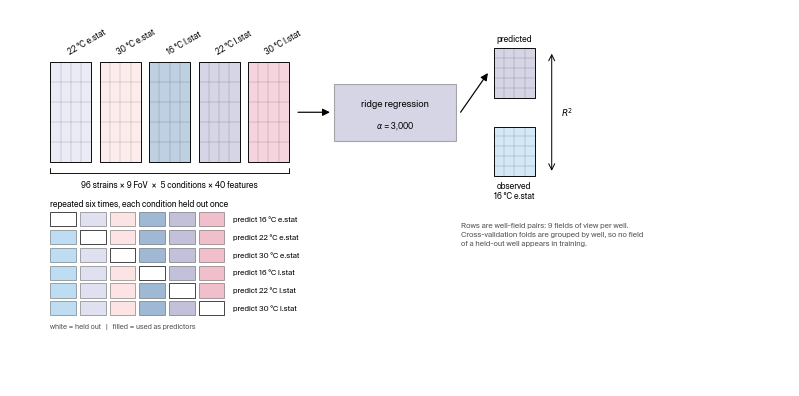

In [183]:
importlib.reload(cba)

fig, ax = cba.plot_model_schematic(
    condition_labels=["16 °C e.stat", "22 °C e.stat", "30 °C e.stat",
                      "16 °C l.stat", "22 °C l.stat", "30 °C l.stat"],
    condition_colors=[apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy],
    held_out_index=0,
    n_rows_label="96 strains × 9 FoV",
    n_features=len(training_feature_labels),
    ridge_alpha=3000,
    save=True,
    figtitle="model_schematic",
)

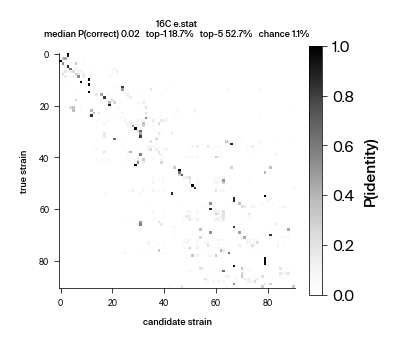

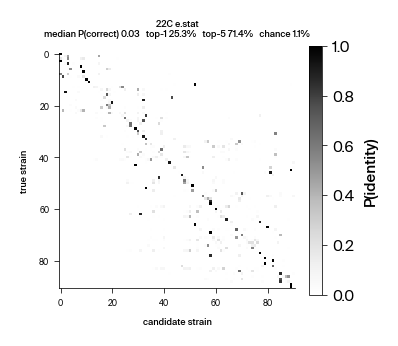

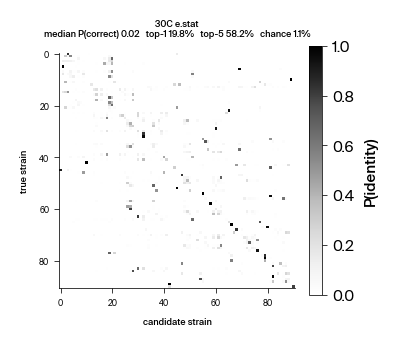

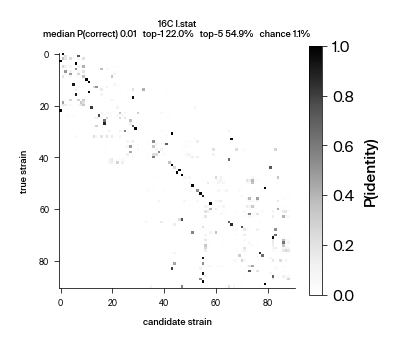

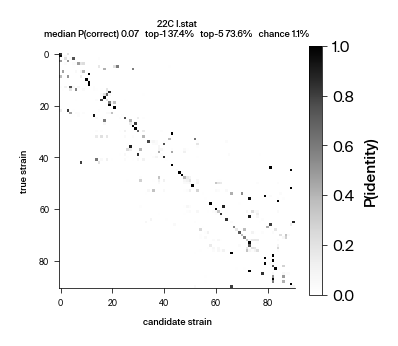

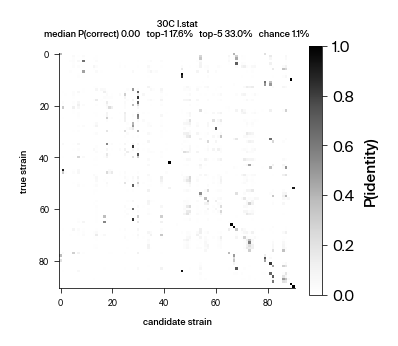

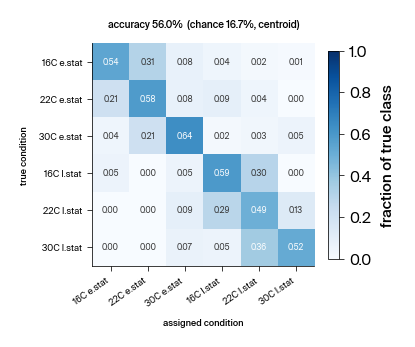

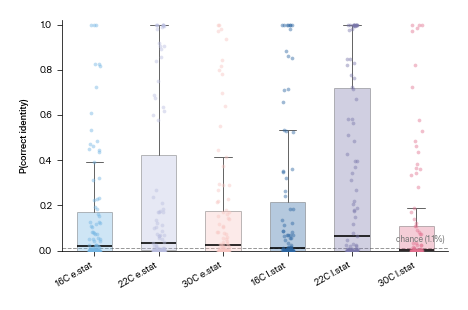

In [286]:
reload(cba)
well_groups = cba.well_groups(96, n_fovs_2_analyze)

# strain identity, one confusion matrix per condition
strain_id = cba.identify_strains_from_predictions(
    training_data_finite, exp_conditions,
    ridge_alpha=3000, n_splits=16, groups=well_groups,
    n_wells=96, n_fovs=n_fovs_2_analyze, dead_ids=dead_ids,
)
cba.plot_strain_identification(strain_id, exp_conditions, col_titles,
                               save=True, figtitle="strain_identification")

# condition identity, one matrix overall
cond_id = cba.identify_condition_from_phenotype(
    training_data_finite, exp_conditions, method="centroid",
    n_wells=96, n_fovs=n_fovs_2_analyze, dead_ids=dead_ids,
)
cba.plot_condition_identification(cond_id, col_titles,
                                  save=True, figtitle="condition_identification")

fig, ax, pdf = cba.plot_identity_probability_distribution(
    strain_id, exp_conditions, col_titles, ytick_colors,
    save=True, figtitle="identity_probability")

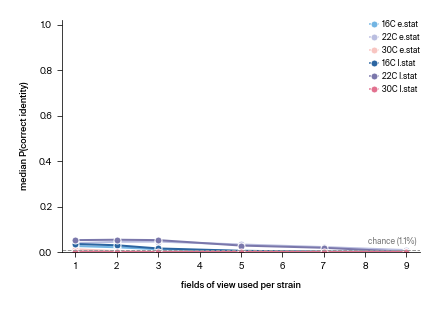

(<Figure size 432x302.4 with 1 Axes>,
 <Axes: xlabel='fields of view used per strain', ylabel='median P(correct identity)'>)

In [49]:
reload(cba)

nfov = cba.identify_strains_vs_n_fov(
    training_data_finite, exp_conditions,
    n_fov_list=(1, 2, 3, 5, 7, 9),
    ridge_alpha=3000, n_splits=16,
    groups=cba.well_groups(96, n_fovs_2_analyze),
    n_wells=96, n_fovs=n_fovs_2_analyze, dead_ids=dead_ids,
    n_repeats=20,
)
cba.plot_identification_vs_n_fov(nfov, exp_conditions, col_titles, ytick_colors,
                                 value_col="median_p_correct",
                                 save=True, figtitle="identification_vs_n_fov")

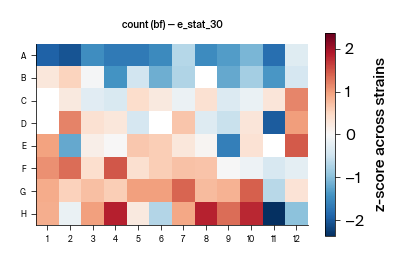

In [50]:
reload(cba)

# 1. how bad is it?
pos = cba.plate_position_effects(
    training_data_finite, exp_conditions, training_feature_labels,
    n_wells=96, n_fovs=n_fovs_2_analyze, dead_ids=dead_ids,
    plate_rows=8, plate_cols=12, layout="row_major",
)
pos.groupby("feature").frac_position.median().sort_values(ascending=False).head(10)

# 2. see it
cba.plot_plate_heatmap(training_data_finite, "e_stat_30", 0, training_feature_labels,
                       n_wells=96, n_fovs=n_fovs_2_analyze, dead_ids=dead_ids)

# 3. correct it
training_data_corrected = cba.correct_positional_effects(
    training_data_finite, exp_conditions,
    n_wells=96, n_fovs=n_fovs_2_analyze, dead_ids=dead_ids,
    plate_rows=8, plate_cols=12, layout="row_major", method="median_polish",
)

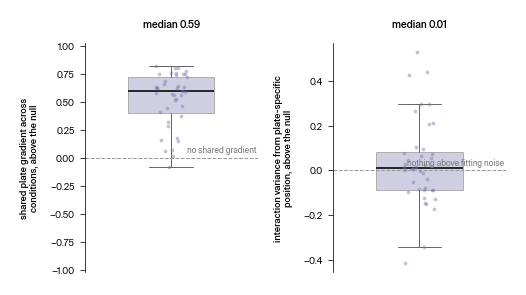

(<Figure size 518.4x288 with 2 Axes>,
 array([<Axes: title={'center': 'median 0.59'}, ylabel='shared plate gradient across\nconditions, above the null'>,
        <Axes: title={'center': 'median 0.01'}, ylabel='interaction variance from plate-specific\nposition, above the null'>],
       dtype=object))

In [287]:
reload(cba)

grad = cba.cross_condition_gradient_consistency(
    training_data_finite, exp_conditions, training_feature_labels,
    n_wells=96, n_fovs=n_fovs_2_analyze, dead_ids=dead_ids,
    plate_rows=8, plate_cols=12, layout="row_major",   # check this first
    n_null=20,
)
grad.excess_interaction_from_position.median()
cba.plot_gradient_consistency(grad, save=True,
                              figtitle="cross_condition_gradient_consistency")

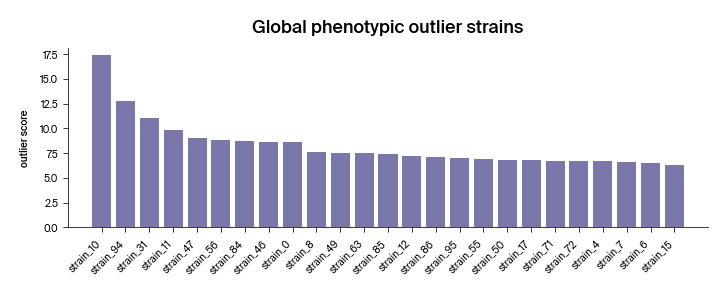

In [54]:
reload(cvp)

outlier_df, condition_distance_df = cvp.compute_global_strain_outlier_scores(
    #training_data=training_data_finite,
    training_data=training_data_finite,
    condition_order=exp_conditions,
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    distance_metric="euclidean",
    aggregate="mean",
    zscore_features_across_strains=True,
    return_condition_distances=True,
)

outlier_df.head(10)

fig, ax = cvp.plot_global_strain_outlier_scores(
    outlier_df,
    top_n=25,
    score_column="outlier_score",
    orientation="vertical",
    figsize=(10, 4),
    save=True,
    figtitle="global_strain_outlier_scores"
)

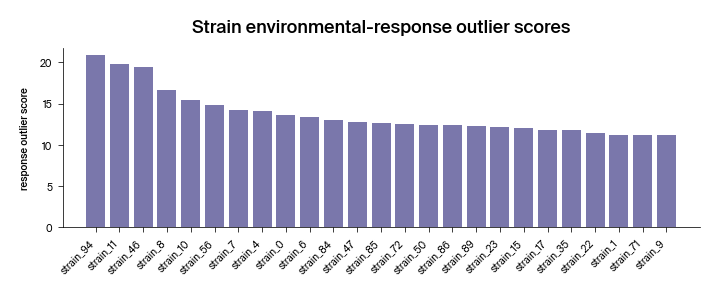

In [55]:
reload(cvp)

response_outlier_df, response_matrix_df = cvp.compute_strain_response_outlier_scores(
    #training_data=training_data_finite,
    training_data=training_data_finite,
    condition_order=exp_conditions,
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    distance_metric="euclidean",
    zscore_within_condition=True,
    center_within_strain=True,
    return_response_matrix=True,
)

response_outlier_df.head(60)

fig, ax = cvp.plot_strain_response_outlier_scores(
    response_outlier_df,
    top_n=25,
    orientation="vertical",
    figsize=(10, 4),
    save=True,
    figtitle="strain_response_outlier_scores"
)

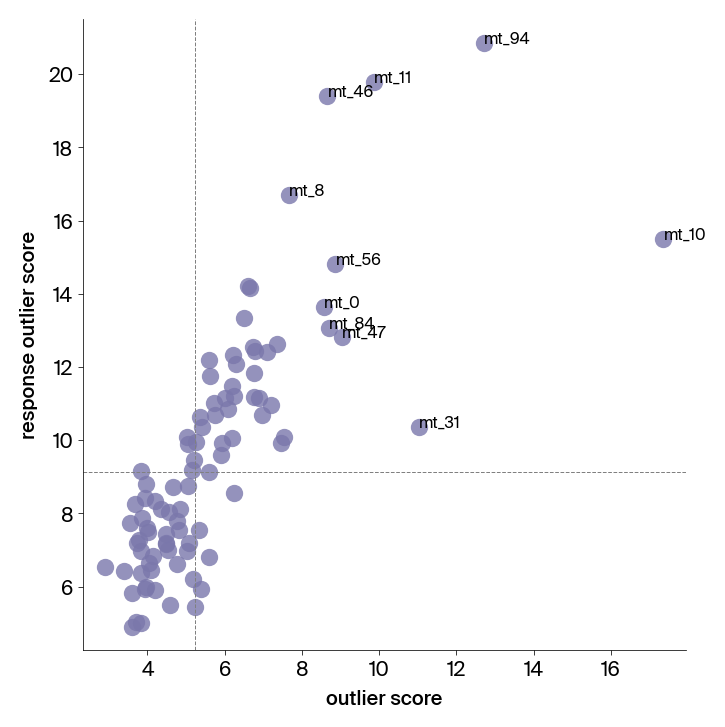

In [56]:
reload(cvp)

fig, ax, merged_outlier_df = cvp.plot_global_vs_response_outlier_scores(
    global_outlier_df=outlier_df,
    response_outlier_df=response_outlier_df,
    annotate_top_n=10,
    annotate_by="sum",
    figsize=(10, 10),
    show_title=False,
    save=True,
    figtitle="global_vs_response_outlier_scores"
)

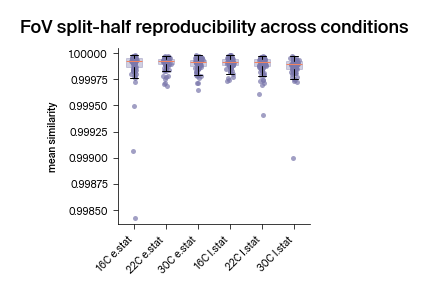

In [57]:
reload(cvp)

reproducibility_df, null_df = cvp.compute_fov_split_half_reproducibility(
    #training_data=training_data_finite,
    training_data=training_data_finite,
    condition_order=exp_conditions,
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    n_splits=16,
    similarity_metric="pearson",
    random_state=42,
    return_null=True,
)

fig, ax = cvp.plot_fov_split_half_reproducibility(
    reproducibility_df,
    condition_order=exp_conditions,
    col_titles=['16C e.stat', '22C e.stat', '30C e.stat',
                '16C l.stat', '22C l.stat', '30C l.stat'],
    ytick_colors=[apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy],
    metric_col="mean_similarity",
    figsize=(4, 4),
    save=True,
    figtitle="fov_split_half_reproducibility"
)

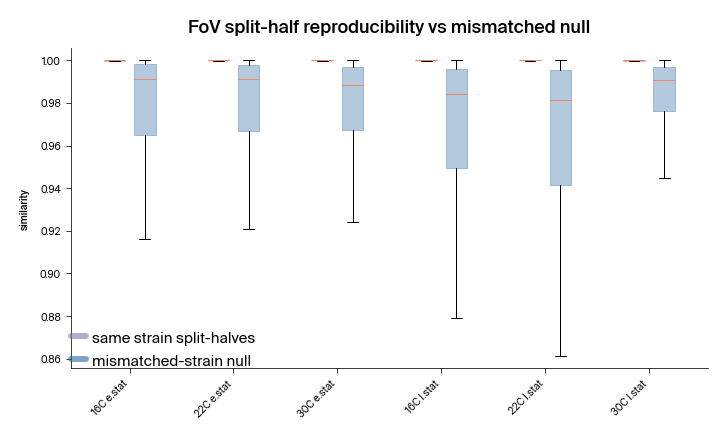

In [58]:
reload(cvp)
fig, ax = cvp.plot_fov_split_half_vs_null(
    reproducibility_df=reproducibility_df,
    null_df=null_df,
    condition_order=exp_conditions,
    col_titles=['16C e.stat', '22C e.stat', '30C e.stat',
                '16C l.stat', '22C l.stat', '30C l.stat'],
    xtick_colors=[apc.vital, apc.wish, apc.dress, apc.lapis, apc.aster, apc.candy],
    metric_col="mean_similarity",
    figsize=(10, 6),
    save=True,
    figtitle="fov_split_half_vs_null"
)

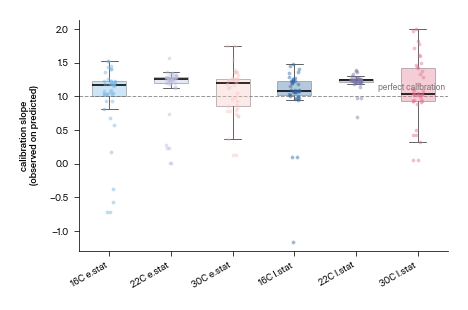

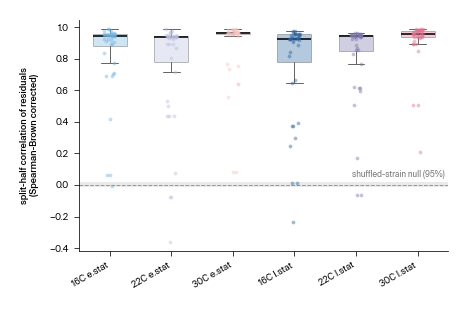

(<Figure size 460.8x302.4 with 1 Axes>,
 <Axes: ylabel='split-half correlation of residuals\n(Spearman-Brown corrected)'>)

In [293]:
reload(cba)
well_groups = cba.well_groups(96, n_fovs_2_analyze)

calib = cba.compute_prediction_calibration(
    training_data_finite, 
    exp_conditions, 
    training_feature_labels,
    ridge_alpha=3000, 
    n_splits=16, 
    groups=well_groups,
    n_wells=96, 
    n_fovs=n_fovs_2_analyze, 
    dead_ids=dead_ids,
)
cba.plot_prediction_calibration(calib, 
                                exp_conditions, 
                                col_titles, 
                                ytick_colors,
                                save=True, 
                                figtitle="prediction_calibration_slopes")

resid = cba.compute_residual_reproducibility(
    training_data_finite, exp_conditions, training_feature_labels,
    ridge_alpha=3000, n_splits=16, groups=well_groups,
    n_wells=96, n_fovs=n_fovs_2_analyze, dead_ids=dead_ids, n_repeats=100,
)
cba.plot_residual_reproducibility(resid, exp_conditions, col_titles, ytick_colors,
                                  save=True, figtitle="residual_reproducibility")

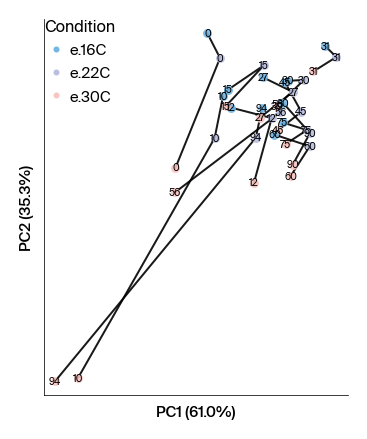

(<Figure size 360x432 with 1 Axes>,
 <Axes: xlabel='PC1 (61.0%)', ylabel='PC2 (35.3%)'>)

In [60]:
reload(cvp)


cvp.plot_strain_pca_trajectories(
    #training_data=training_data_finite,
    training_data=training_data_finite,
    exp_conditions=["e_stat_16", "e_stat_22", "e_stat_30"],
    pca_conditions=["e_stat_16", "e_stat_22", "e_stat_30",
                    "l_stat_16", "l_stat_22", "l_stat_30"],
    strains_to_plot=[10, 12, 27, 31, 94, 56,0,15,30,45,60,75,90],
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    condition_labels=["e.16C", "e.22C", "e.30C"],
    condition_colors=[apc.vital, apc.wish, apc.dress],
    fit_pca_on="all_strains",
    show_variance_explained=True,
    show_title=False,
    figsize=(5, 6),
    save=True,
    figtitle="strain_pca_trajectories_selected_fit_on_all_early_stat"
)

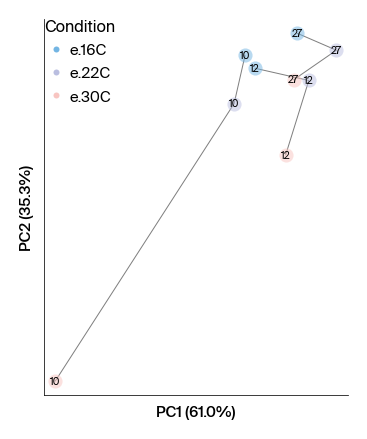

(<Figure size 360x432 with 1 Axes>,
 <Axes: xlabel='PC1 (61.0%)', ylabel='PC2 (35.3%)'>)

In [66]:
reload(cvp)


cvp.plot_strain_pca_trajectories(
    #training_data=training_data_finite,
    training_data=training_data_finite,
    exp_conditions=["e_stat_16", "e_stat_22", "e_stat_30"],
    pca_conditions=["e_stat_16", "e_stat_22", "e_stat_30",
                    "l_stat_16", "l_stat_22", "l_stat_30"],
    strains_to_plot=[10, 12, 27],
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    point_size=200,
    line_width=1,
    alpha=0.5,
    annotate_points=True,
    condition_labels=["e.16C", "e.22C", "e.30C"],
    condition_colors=[apc.vital, apc.wish, apc.dress],
    fit_pca_on="all_strains",
    show_variance_explained=True,
    show_title=False,
    figsize=(5, 6),
    save=True,
    figtitle="strain_10_12_27__pca_trajectories_selected_fit_on_all_early_stat"
)

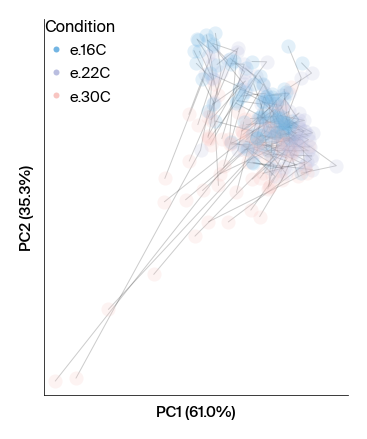

(<Figure size 360x432 with 1 Axes>,
 <Axes: xlabel='PC1 (61.0%)', ylabel='PC2 (35.3%)'>)

In [67]:
reload(cvp)

all_strains=list(range(96))
for n in dead_wells:
    all_strains.remove(n)


cvp.plot_strain_pca_trajectories(
    #training_data=training_data_finite,
    training_data=training_data_finite,
    exp_conditions=["e_stat_16", "e_stat_22", "e_stat_30"],
    pca_conditions=["e_stat_16", "e_stat_22", "e_stat_30",
                    "l_stat_16", "l_stat_22", "l_stat_30"],
    strains_to_plot=all_strains,
    n_wells=96,
    point_size=200,
    line_width=1,
    alpha=0.2,
    annotate_points=False,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    condition_labels=["e.16C", "e.22C", "e.30C"],
    condition_colors=[apc.vital, apc.wish, apc.dress],
    fit_pca_on="all_strains",
    show_variance_explained=True,
    show_title=False,
    figsize=(5, 6),
    save=True,
    figtitle="all_strains_pca_trajectories_selected_fit_on_all_early_stat"
)

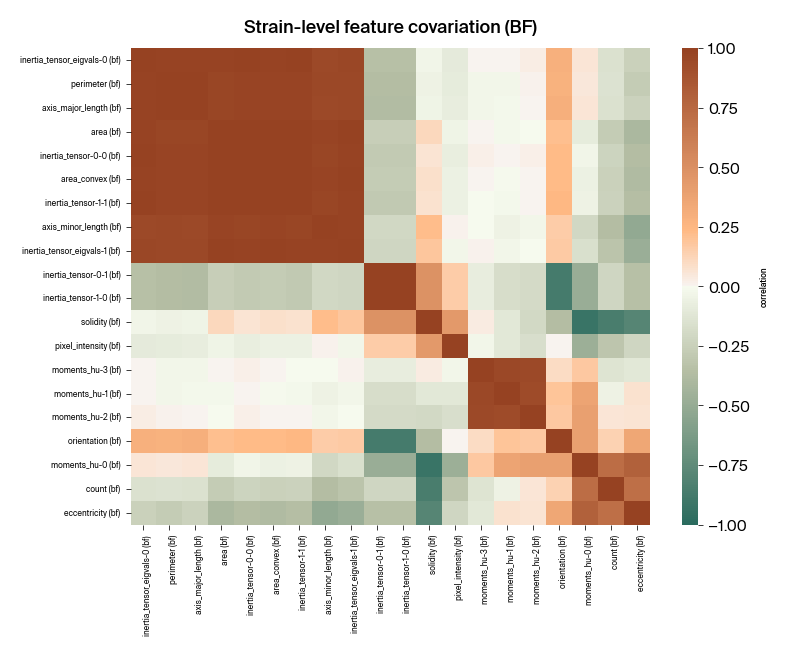

In [68]:
reload(cvp)

corr_df, feature_table_df = cvp.compute_feature_covariation_matrix(
    zroots=zroots,
    channel="BF",
    exp_conditions=[0, 1, 2, 3, 4, 5],
    condition_labels=["e.16C", "e.22C", "e.30C", "l.16C", "l.22C", "l.30C"],
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    include_pixel_intensity=True,
    exclude_features=["moments_hu-4", "moments_hu-5", "moments_hu-6"],
    summary_level="strain",
    summary_method="mean",
    correlation_method="pearson",
    return_feature_table=True,
)

fig, ax, plot_df = cvp.plot_feature_covariation_heatmap(
    corr_df,
    figsize=(11, 9),
    cluster=True,
    save=True,
    title="Strain-level feature covariation (BF)",
    figtitle="feature_covariation_heatmap_bf"
)

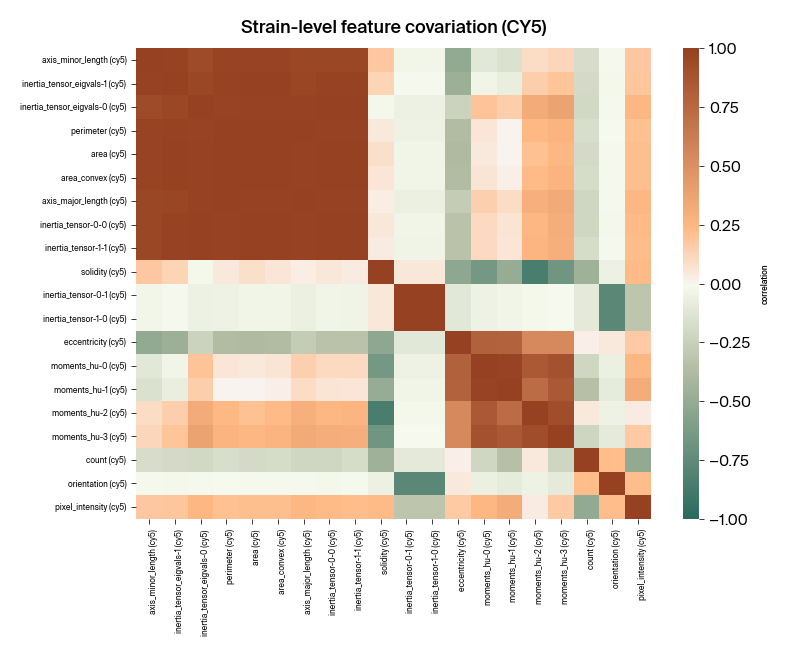

In [69]:
reload(cvp)

corr_df_cy5, feature_table_df_cy5 = cvp.compute_feature_covariation_matrix(
    zroots=zroots,
    channel="CY5",
    exp_conditions=[0, 1, 2, 3, 4, 5],
    condition_labels=["e.16C", "e.22C", "e.30C", "l.16C", "l.22C", "l.30C"],
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    include_pixel_intensity=True,
    exclude_features=["moments_hu-4", "moments_hu-5", "moments_hu-6"],
    summary_level="strain",
    summary_method="mean",
    correlation_method="pearson",
    return_feature_table=True,
)

fig, ax, plot_df = cvp.plot_feature_covariation_heatmap(
    corr_df_cy5,
    figsize=(11, 9),
    cluster=True,
    save=True,
    title="Strain-level feature covariation (CY5)",
    figtitle="feature_covariation_heatmap_cy5")


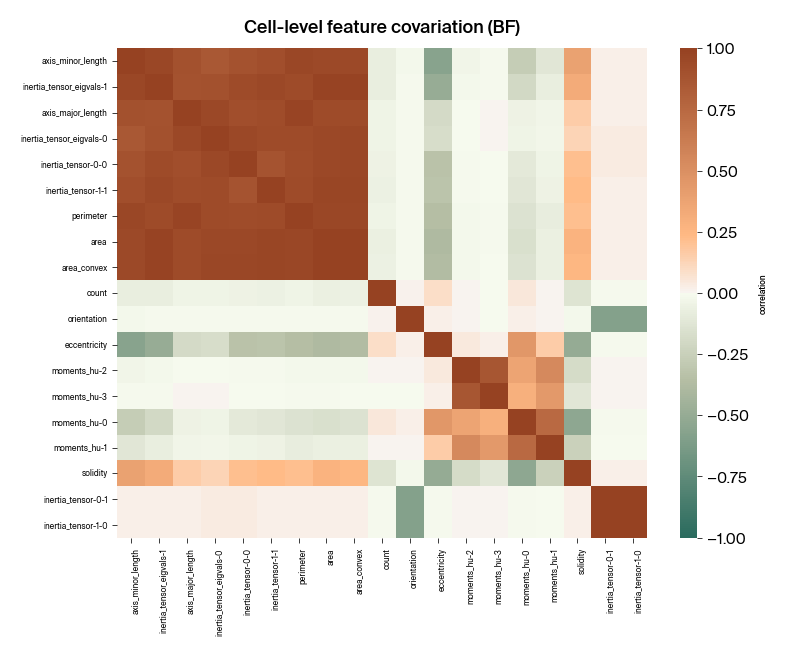

In [70]:
corr_cell_bf, cell_df_bf = cvp.compute_feature_covariation_matrix_cell_level(
    zroots=zroots,
    exclude_features=["moments_hu-4", "moments_hu-5", "moments_hu-6"],
    channel="BF",
    exp_conditions=[0, 1, 2, 3, 4, 5],
    condition_labels=["e.16C", "e.22C", "e.30C", "l.16C", "l.22C", "l.30C"],
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    max_cells_per_well=200  # optional speed control
)
fig_pfch, ax_pfch, plot_df_pfch = cvp.plot_feature_covariation_heatmap(
    corr_cell_bf,
    figsize=(11, 9),
    cluster=True,
    title="Cell-level feature covariation (BF)",
    save=True,
    figtitle="feature_covariation_heatmap_cell_level_bf",
)

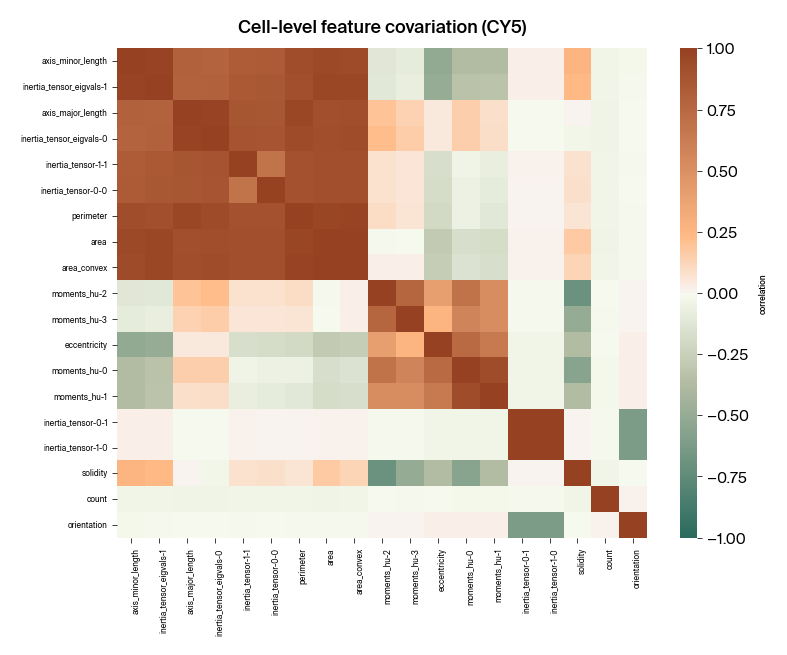

In [71]:
corr_cell_cy5, cell_df_cy5 = cvp.compute_feature_covariation_matrix_cell_level(
    zroots=zroots,
    exclude_features=["moments_hu-4", "moments_hu-5", "moments_hu-6"],
    channel="CY5",
    exp_conditions=[0, 1, 2, 3, 4, 5],
    condition_labels=["e.16C", "e.22C", "e.30C", "l.16C", "l.22C", "l.30C"],
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    max_cells_per_well=200  # optional speed control
)

fig_pfch_cy5, ax_pfch_cy5, plot_df_pfch_cy5 = cvp.plot_feature_covariation_heatmap(
    corr_cell_cy5,
    figsize=(11, 9),
    cluster=True,
    title="Cell-level feature covariation (CY5)",
    save=True,
    figtitle="feature_covariation_heatmap_cell_level_cy5",
)

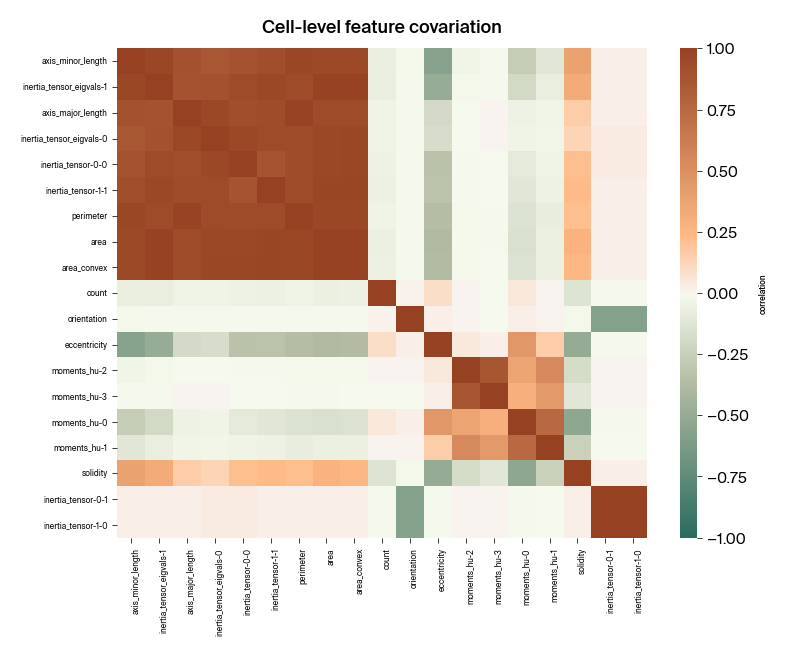

In [144]:
fig_pfch, ax_pfch, plot_df_pfch = cvp.plot_feature_covariation_heatmap(
    corr_cell_bf,
    figsize=(11, 9),
    cluster=True,
    title="Cell-level feature covariation",
    save=True,
    figtitle="feature_covariation_heatmap_cell_level_bf",
)

In [165]:
reload(cvp)

#find the cells with the lowest and highest axis_major_length that fall within the same size range

res = cvp.find_feature_extremes_within_size_band(
    zroots=zroots,
    target_feature="axis_major_length",
    size_feature="area",
    channel="BF",
    exp_conditions=[0, 1, 2, 3, 4, 5],
    condition_labels=["e.16C", "e.22C", "e.30C", "l.16C", "l.22C", "l.30C"],
    n_wells=96,
    n_fovs=n_fovs_2_analyze,
    dead_ids=dead_ids,
    top_n_cells=20,
    size_percentile_low=74.0,
    size_percentile_high=76.0,
    abs_value_target=False,
    abs_value_size=False,
    return_all_cells_df=True,
)

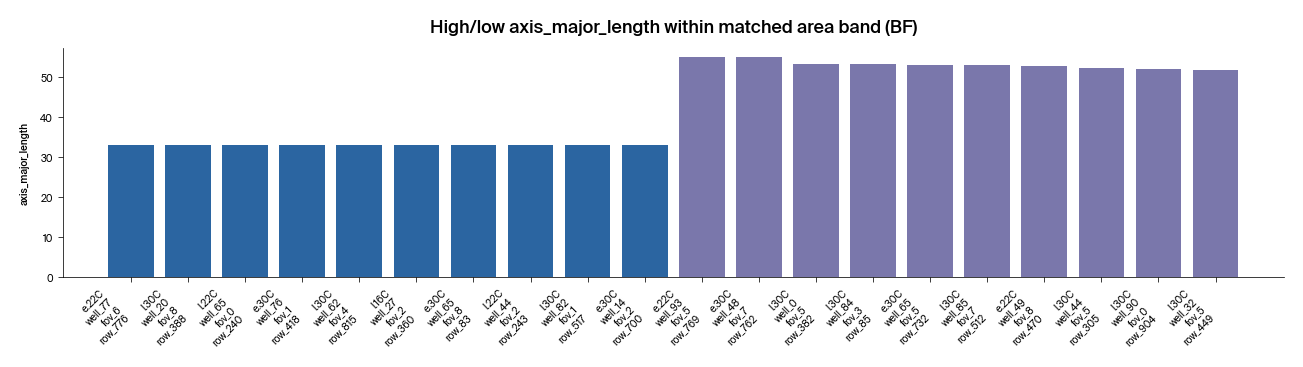

In [169]:
fig, ax, plot_df = cvp.plot_feature_extremes_within_size_band(
    res,
    top_n=10,
    figsize=(18, 5),
    save=True,
    figtitle="axis_major_length_within_area_band"
)

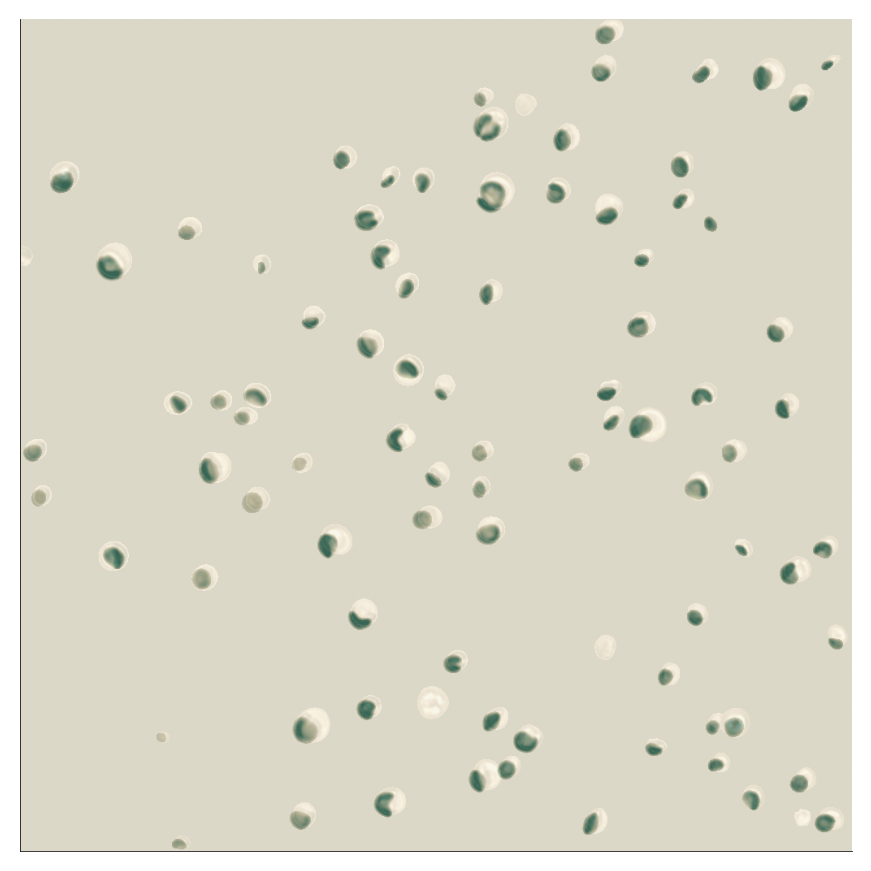

In [168]:
#cell 189 has the highest inertia tensor 1-1 with matched area in cy5 band
cvp.showcase_clone_images_1_by_1(zroots,
                             experiment=3,
                             field_of_view=0,
                             well=1,
                             f_size=[8, 8],
                             f_size_2=[15, 15],
                             show_labels=False,
                             marker_size_1=6,
                             marker_size_2=10,
                             show_only_merged=True,
                             marker_color_bf='yellow',
                             marker_color_cy='red')

# 

# 